In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd

# Read the CSV file into a pandas DataFrame
df = pd.read_csv('/content/drive/MyDrive/My work/Air Quality Project/Paper 1(External Data)/New/merged_aqi_corrected_cleaned.csv')

# Display the first few rows of the DataFrame
display(df.head())

,Date,Time,Location,PM2.5,PM10,NO2,O3,CO,SO2,AQI,AQI_Category
0,11/5/2012,14:00,Sangsad,16.13,27.09,4.90,3.29,0.47,10.99,27.0,Good
1,11/5/2012,15:00,Sangsad,19.90,30.45,4.91,4.58,0.45,10.89,33.0,Good
2,11/5/2012,16:00,Sangsad,17.10,43.94,4.80,4.96,0.45,11.28,44.0,Good
3,11/5/2012,18:00,Sangsad,15.58,41.43,4.51,3.06,0.57,11.83,41.0,Good
4,11/5/2012,19:00,Sangsad,32.94,54.17,4.51,2.96,0.56,12.00,54.0,Satisfactory


In [ ]:
display(df.columns)

Index(['Date', 'Time', 'Location', 'PM2.5', 'PM10', 'NO2', 'O3', 'CO', 'SO2',
       'AQI', 'AQI_Category'],
      dtype='object')

In [ ]:
# Generate descriptive statistics for numerical columns
descriptive_stats = df.describe()

# Display the descriptive statistics
display(descriptive_stats)

,PM2.5,PM10,NO2,O3,CO,SO2,AQI
count,271326.000000,271326.000000,271326.000000,271326.000000,271326.000000,271326.000000,262484.000000
mean,75.473059,119.667577,6.370692,4.118237,2.570997,3.346433,144.988308
std,58.440214,97.227447,12.495334,9.155519,1.645193,11.170507,79.576078
min,0.000000,0.000000,0.010000,0.000000,0.000000,0.000000,9.000000
25%,45.000000,65.431250,0.040000,0.180000,1.250000,0.030000,116.000000
50%,63.000000,100.000000,0.140000,0.430000,3.300000,0.060000,120.000000
75%,76.000000,119.000000,8.285200,3.500000,3.500000,2.820000,149.000000
max,985.000000,2106.290000,266.750000,137.620000,79.810000,299.940000,400.000000


In [ ]:
# Calculate the number of missing values for each column
missing_values = df.isnull().sum()

# Display the count of missing values
print("Number of missing values per column:")
display(missing_values)

# Calculate the percentage of missing values for each column
missing_percentage = (missing_values / len(df)) * 100

# Display the percentage of missing values
print("\nPercentage of missing values per column:")
display(missing_percentage)

Number of missing values per column:


,0
Date,8195
Time,0
Location,0
PM2.5,0
PM10,0
NO2,0
O3,0
CO,0
SO2,0
AQI,8842



Percentage of missing values per column:


,0
Date,3.020352
Time,0.000000
Location,0.000000
PM2.5,0.000000
PM10,0.000000
NO2,0.000000
O3,0.000000
CO,0.000000
SO2,0.000000
AQI,3.258810


In [ ]:
# Get the number of unique values in the 'AQI_Category' column
num_unique_aqi_categories = df['AQI_Category'].nunique()

# Display the number of unique values
print(f"Number of unique AQI categories: {num_unique_aqi_categories}")

# Optionally, display the unique categories themselves
print("\nUnique AQI categories:")
display(df['AQI_Category'].unique())

Number of unique AQI categories: 6

Unique AQI categories:


array(['Good', 'Satisfactory', 'Moderate', 'Very Poor', 'Poor', 'Severe'],
      dtype=object)

In [ ]:
# Get the value counts for the 'AQI_Category' column
aqi_category_counts = df['AQI_Category'].value_counts()

# Display the value counts
print("Occurrence of each AQI Category:")
display(aqi_category_counts)

Occurrence of each AQI Category:


,count
AQI_Category,
Moderate,170940
Satisfactory,37263
Very Poor,28081
Poor,14400
Good,11800
Severe,8842


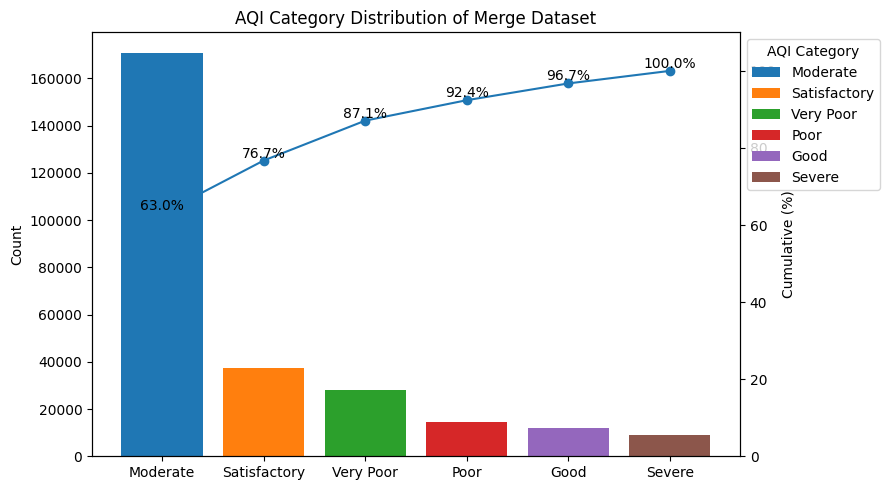

In [ ]:
# Pareto chart for AQI Category (Set 3) with different color per label

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

# Data (Set 3)
data = {
    "Moderate": 170940,
    "Satisfactory": 37263,
    "Very Poor": 28081,
    "Poor": 14400,
    "Good": 11800,
    "Severe":8842
}

# Sort by count (descending)
labels, counts = zip(*sorted(data.items(), key=lambda kv: kv[1], reverse=True))
counts = np.array(counts, dtype=float)
cum_pct = np.cumsum(counts) / counts.sum() * 100.0
x = np.arange(len(labels))

# Different color per label (from matplotlib tab10 palette)
palette = list(plt.cm.tab10.colors)
bar_colors = [palette[i % len(palette)] for i in range(len(labels))]

# Plot bars
fig = plt.figure(figsize=(9, 5))
plt.bar(x, counts, color=bar_colors)
plt.xticks(x, labels)
plt.ylabel("Count")
plt.title("AQI Category Distribution of Merge Dataset")

# Cumulative line (secondary axis)
ax2 = plt.gca().twinx()
ax2.plot(x, cum_pct, marker="o")
ax2.set_ylabel("Cumulative (%)")
ax2.set_ylim(0, 110)

# Annotate cumulative percentages
for i, cp in enumerate(cum_pct):
    ax2.text(i, cp, f"{cp:.1f}%", ha="center", va="bottom")

# Optional legend mapping colors to labels
handles = [Patch(facecolor=bar_colors[i], edgecolor="none", label=labels[i]) for i in range(len(labels))]
plt.legend(handles=handles, title="AQI Category", loc="upper left", bbox_to_anchor=(1, 1))

plt.tight_layout()
plt.savefig("AQI_Pareto_Set3_colored.png", dpi=200, bbox_inches="tight")
plt.show()


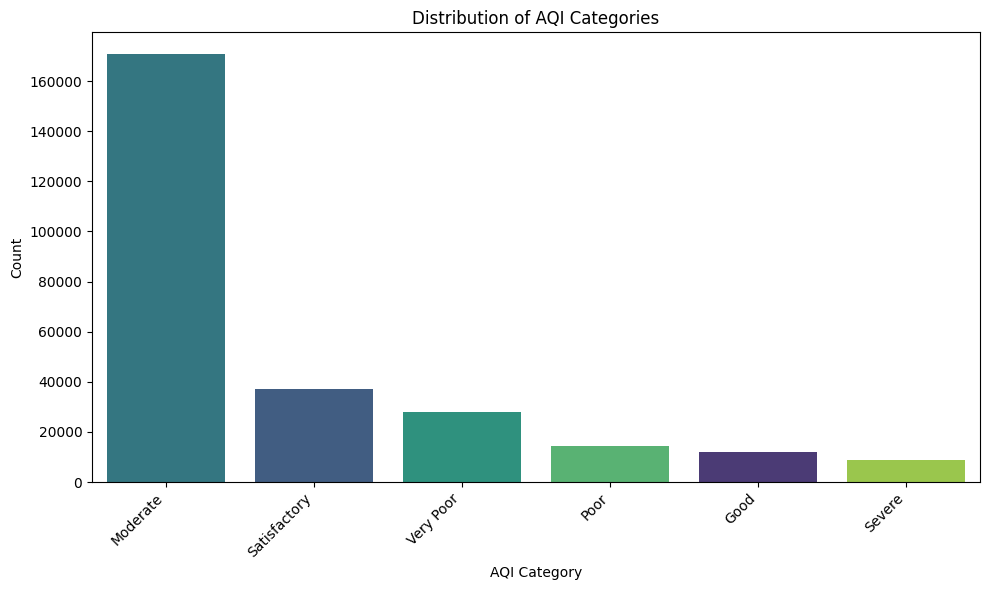

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a bar plot of AQI category counts
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='AQI_Category', order=df['AQI_Category'].value_counts().index, palette='viridis', hue='AQI_Category', legend=False)
plt.title('Distribution of AQI Categories')
plt.xlabel('AQI Category')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Task
Perform exploratory data analysis (EDA) on the dataframe.

In [ ]:
# Display the first 5 rows of the DataFrame
display(df.head())

# Display the column names of the DataFrame
display(df.columns)

# Display the data types of each column in the DataFrame
display(df.info())

,Date,Time,Location,PM2.5,PM10,NO2,O3,CO,SO2,AQI,AQI_Category
0,11/5/2012,14:00,Sangsad,16.13,27.09,4.90,3.29,0.47,10.99,27.0,Good
1,11/5/2012,15:00,Sangsad,19.90,30.45,4.91,4.58,0.45,10.89,33.0,Good
2,11/5/2012,16:00,Sangsad,17.10,43.94,4.80,4.96,0.45,11.28,44.0,Good
3,11/5/2012,18:00,Sangsad,15.58,41.43,4.51,3.06,0.57,11.83,41.0,Good
4,11/5/2012,19:00,Sangsad,32.94,54.17,4.51,2.96,0.56,12.00,54.0,Satisfactory


Index(['Date', 'Time', 'Location', 'PM2.5', 'PM10', 'NO2', 'O3', 'CO', 'SO2',
       'AQI', 'AQI_Category'],
      dtype='object')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 271326 entries, 0 to 271325
Data columns (total 11 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   Date          263131 non-null  object 
 1   Time          271326 non-null  object 
 2   Location      271326 non-null  object 
 3   PM2.5         271326 non-null  float64
 4   PM10          271326 non-null  float64
 5   NO2           271326 non-null  float64
 6   O3            271326 non-null  float64
 7   CO            271326 non-null  float64
 8   SO2           271326 non-null  float64
 9   AQI           262484 non-null  float64
 10  AQI_Category  271326 non-null  object 
dtypes: float64(7), object(4)
memory usage: 22.8+ MB


None

## Get summary statistics

### Subtask:
Generate descriptive statistics for numerical columns to understand their distribution, central tendency, and spread.


In [ ]:
# Generate descriptive statistics for numerical columns
descriptive_stats = df.describe()

# Display the descriptive statistics
display(descriptive_stats)

,PM2.5,PM10,NO2,O3,CO,SO2,AQI
count,271326.000000,271326.000000,271326.000000,271326.000000,271326.000000,271326.000000,262484.000000
mean,75.473059,119.667577,6.370692,4.118237,2.570997,3.346433,144.988308
std,58.440214,97.227447,12.495334,9.155519,1.645193,11.170507,79.576078
min,0.000000,0.000000,0.010000,0.000000,0.000000,0.000000,9.000000
25%,45.000000,65.431250,0.040000,0.180000,1.250000,0.030000,116.000000
50%,63.000000,100.000000,0.140000,0.430000,3.300000,0.060000,120.000000
75%,76.000000,119.000000,8.285200,3.500000,3.500000,2.820000,149.000000
max,985.000000,2106.290000,266.750000,137.620000,79.810000,299.940000,400.000000


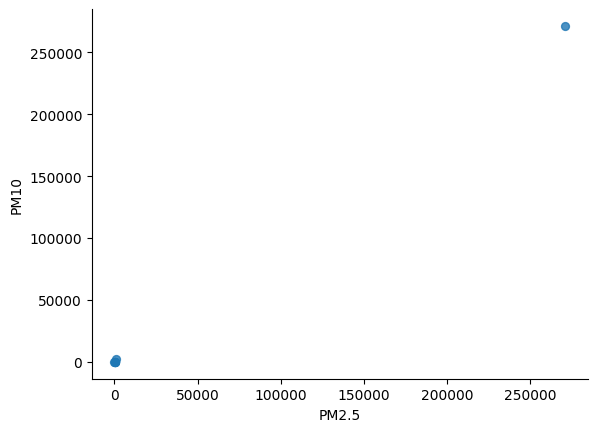

In [ ]:
# @title PM2.5 vs PM10

from matplotlib import pyplot as plt
descriptive_stats.plot(kind='scatter', x='PM2.5', y='PM10', s=32, alpha=.8)
plt.gca().spines[['top', 'right',]].set_visible(False)

## Check for missing values

### Subtask:
Identify missing values in each column and visualize their distribution.


Number of missing values per column:


,0
Date,8195
Time,0
Location,0
PM2.5,0
PM10,0
NO2,0
O3,0
CO,0
SO2,0
AQI,8842



Percentage of missing values per column:


,0
Date,3.020352
Time,0.000000
Location,0.000000
PM2.5,0.000000
PM10,0.000000
NO2,0.000000
O3,0.000000
CO,0.000000
SO2,0.000000
AQI,3.258810


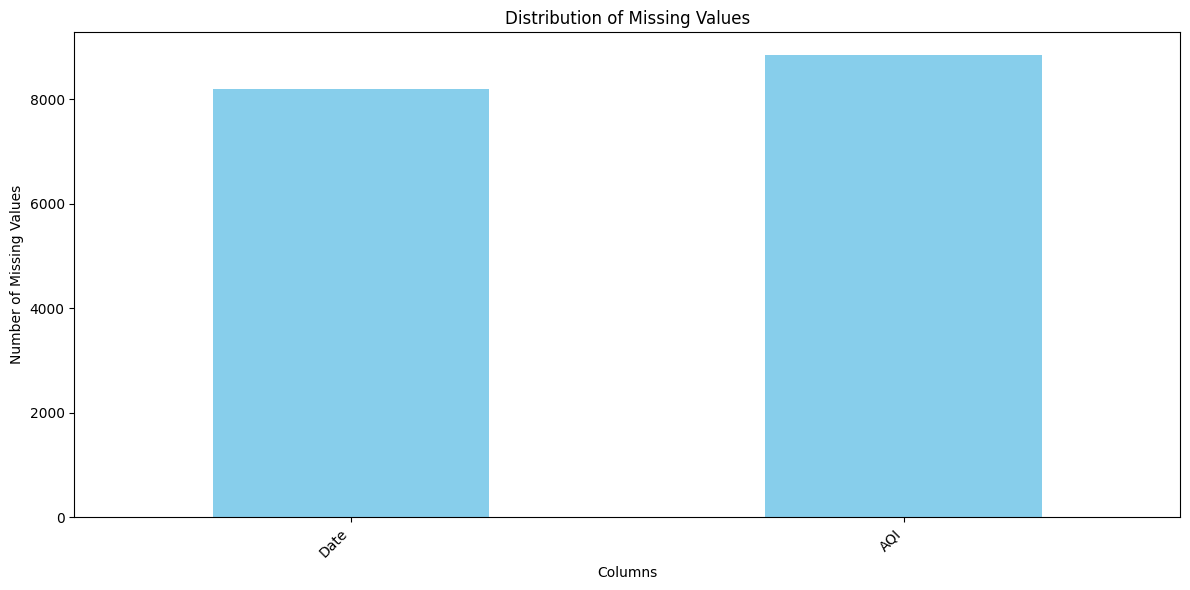

In [ ]:
# Calculate the number of missing values for each column
missing_values = df.isnull().sum()

# Display the count of missing values
print("Number of missing values per column:")
display(missing_values)

# Calculate the percentage of missing values for each column
missing_percentage = (missing_values / len(df)) * 100

# Display the percentage of missing values
print("\nPercentage of missing values per column:")
display(missing_percentage)

# Create a bar plot to visualize the distribution of missing values
plt.figure(figsize=(12, 6))
missing_values[missing_values > 0].plot(kind='bar', color='skyblue')
plt.title('Distribution of Missing Values')
plt.xlabel('Columns')
plt.ylabel('Number of Missing Values')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## Analyze unique values

### Subtask:
Examine unique values and their counts for categorical columns.


In [ ]:
# Identify categorical columns (excluding Date and Time)
categorical_cols = ['Location', 'AQI_Category']

for col in categorical_cols:
    # Get the number of unique values
    num_unique = df[col].nunique()
    print(f"\nNumber of unique values in '{col}': {num_unique}")

    # Get and display the unique values
    unique_values = df[col].unique()
    print(f"Unique values in '{col}':")
    display(unique_values)

    # Get and display the frequency counts
    value_counts = df[col].value_counts()
    print(f"Frequency counts for '{col}':")
    display(value_counts)


Number of unique values in 'Location': 19
Unique values in 'Location':


array(['Sangsad', 'BARC', 'Darussalam', 'Gazipur', 'Narayonganj',
       'TV st-Chittagong', 'Agrabad Chittagong', 'Sylhet', 'Khulna',
       'Rajshahi', 'Barishal', 'Savar', 'Rangpur', 'Mymansingh',
       'Cumilla', 'Narsingdi', 'Kuril Bishow Road, Dhaka, Bangladesh',
       'Uttara, Dhaka, Bangladesh', 'Tongi, Gazipur, Bangladesh'],
      dtype=object)

Frequency counts for 'Location':


,count
Location,
"Kuril Bishow Road, Dhaka, Bangladesh",51810
"Uttara, Dhaka, Bangladesh",51800
"Tongi, Gazipur, Bangladesh",51795
Darussalam,18773
Sylhet,14746
BARC,13482
Agrabad Chittagong,13071
Gazipur,11442
Narayonganj,11169



Number of unique values in 'AQI_Category': 6
Unique values in 'AQI_Category':


array(['Good', 'Satisfactory', 'Moderate', 'Very Poor', 'Poor', 'Severe'],
      dtype=object)

Frequency counts for 'AQI_Category':


,count
AQI_Category,
Moderate,170940
Satisfactory,37263
Very Poor,28081
Poor,14400
Good,11800
Severe,8842


In [ ]:
# Filter the DataFrame for the location 'Tongi, Gazipur, Bangladesh'
tongi_data = df[df['Location'] == 'Tongi, Gazipur, Bangladesh']

# Get the value counts for the 'AQI_Category' column in the filtered data
tongi_aqi_category_counts = tongi_data['AQI_Category'].value_counts()

# Display the value counts
print("Occurrence of each AQI Category in Tongi, Gazipur, Bangladesh:")
display(tongi_aqi_category_counts)

Occurrence of each AQI Category in Tongi, Gazipur, Bangladesh:


,count
AQI_Category,
Moderate,48083
Satisfactory,2692
Poor,671
Very Poor,340
Good,9


In [ ]:
# Filter the DataFrame for the location 'Uttara, Dhaka, Bangladesh'
uttara_data = df[df['Location'] == 'Uttara, Dhaka, Bangladesh']

# Get the value counts for the 'AQI_Category' column in the filtered data
uttara_aqi_category_counts = uttara_data['AQI_Category'].value_counts()

# Display the value counts
print("Occurrence of each AQI Category in Uttara, Dhaka, Bangladesh:")
display(uttara_aqi_category_counts)

Occurrence of each AQI Category in Uttara, Dhaka, Bangladesh:


,count
AQI_Category,
Moderate,49349
Satisfactory,1699
Poor,538
Very Poor,205
Good,9


In [ ]:
# Filter the DataFrame for the location 'Kuril Bishow Road, Dhaka, Bangladesh'
kuril_data = df[df['Location'] == 'Kuril Bishow Road, Dhaka, Bangladesh']

# Get the value counts for the 'AQI_Category' column in the filtered data
kuril_aqi_category_counts = kuril_data['AQI_Category'].value_counts()

# Display the value counts
print("Occurrence of each AQI Category in Kuril Bishow Road, Dhaka, Bangladesh:")
display(kuril_aqi_category_counts)

Occurrence of each AQI Category in Kuril Bishow Road, Dhaka, Bangladesh:


,count
AQI_Category,
Moderate,49661
Satisfactory,1642
Poor,370
Very Poor,114
Good,17
Severe,6


In [ ]:
# Get all unique values from the 'Location' column
all_locations = df['Location'].unique()

# Create a list of locations to exclude based on previous analysis
excluded_locations = ['Tongi, Gazipur, Bangladesh', 'Uttara, Dhaka, Bangladesh', 'Kuril Bishow Road, Dhaka, Bangladesh']

# Filter the list of all unique locations to exclude the specified locations
filtered_locations = [location for location in all_locations if location not in excluded_locations]

# Calculate the value counts for the 'AQI_Category' column for each filtered location
for location in filtered_locations:
    location_data = df[df['Location'] == location]
    aqi_category_counts = location_data['AQI_Category'].value_counts()
    print(f"\nOccurrence of each AQI Category in {location}:")
    display(aqi_category_counts)


Occurrence of each AQI Category in Sangsad:


,count
AQI_Category,
Very Poor,790
Satisfactory,607
Good,392
Severe,309
Poor,155
Moderate,97



Occurrence of each AQI Category in BARC:


,count
AQI_Category,
Satisfactory,3849
Very Poor,3605
Moderate,3002
Poor,1683
Good,707
Severe,636



Occurrence of each AQI Category in Darussalam:


,count
AQI_Category,
Satisfactory,5079
Very Poor,4775
Moderate,4254
Poor,1737
Severe,1626
Good,1302


... (22 outputs left out)


Occurrence of each AQI Category in Cumilla:


,count
AQI_Category,
Very Poor,8
Satisfactory,3
Good,1
Poor,1
Severe,1



Occurrence of each AQI Category in Narsingdi:


,count
AQI_Category,
Very Poor,91
Poor,86
Moderate,66
Severe,48
Satisfactory,33
Good,28


## Visualize distributions

### Subtask:
Create plots (histograms, box plots, etc.) to visualize the distribution of key variables.


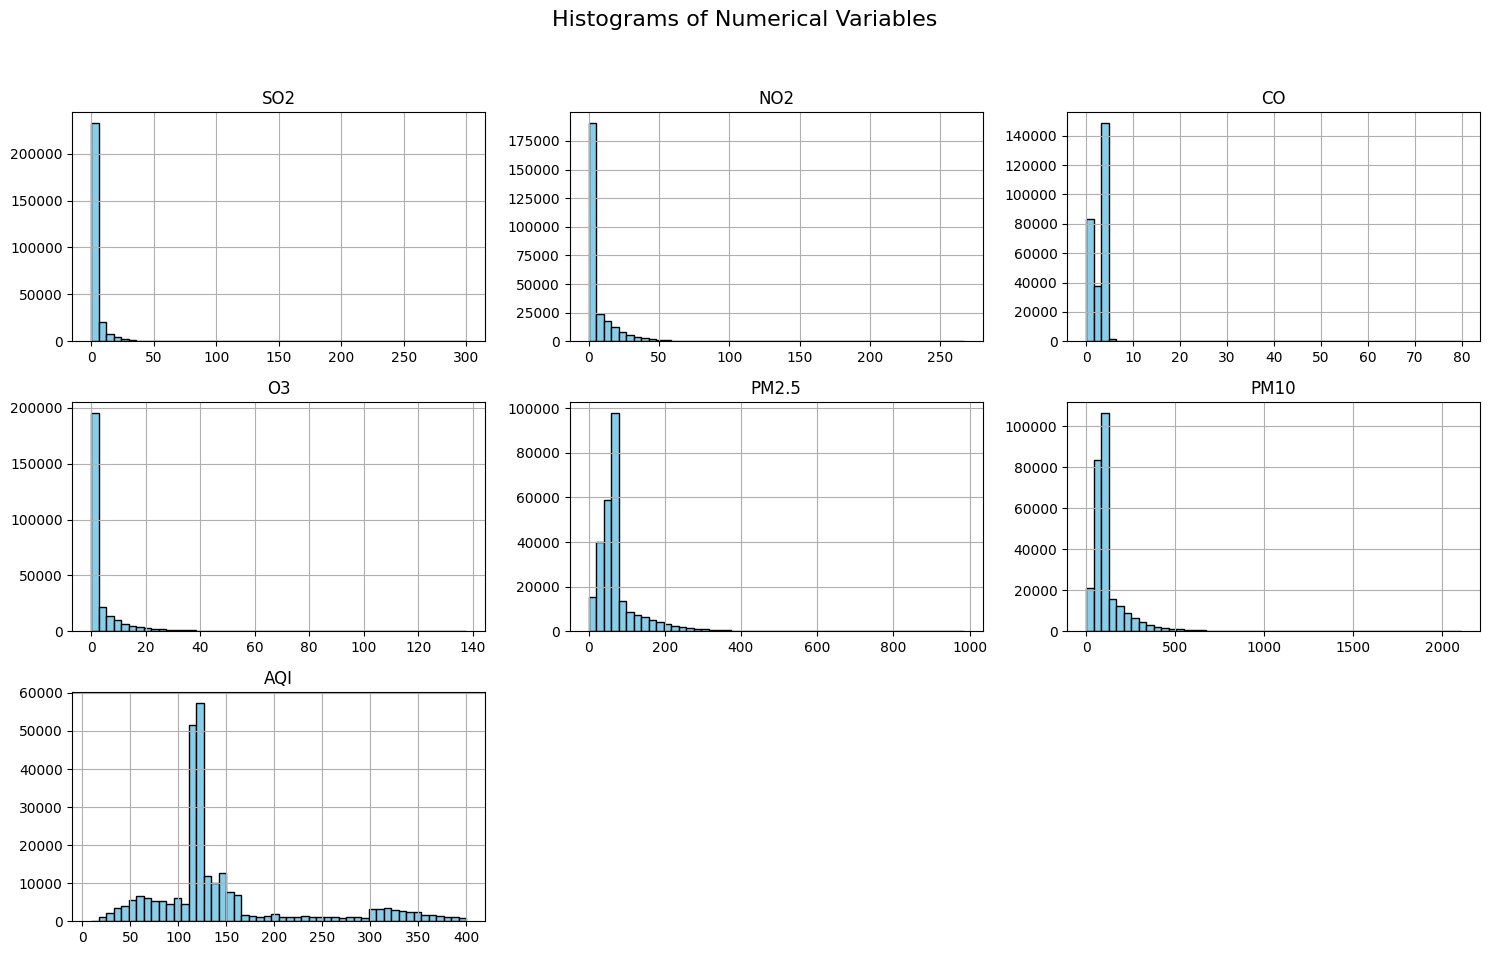

In [ ]:
# Create histograms for numerical columns
numerical_cols = ['SO2', 'NO2', 'CO', 'O3', 'PM2.5', 'PM10', 'AQI']
df[numerical_cols].hist(figsize=(15, 10), bins=50, layout=(3, 3), color='skyblue', edgecolor='black')
plt.suptitle('Histograms of Numerical Variables', size=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

/tmp/ipykernel_44212/3515728459.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=df[col], palette='viridis')
/tmp/ipykernel_44212/3515728459.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=df[col], palette='viridis')
/tmp/ipykernel_44212/3515728459.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=df[col], palette='viridis')
/tmp/ipykernel_44212/3515728459.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for th

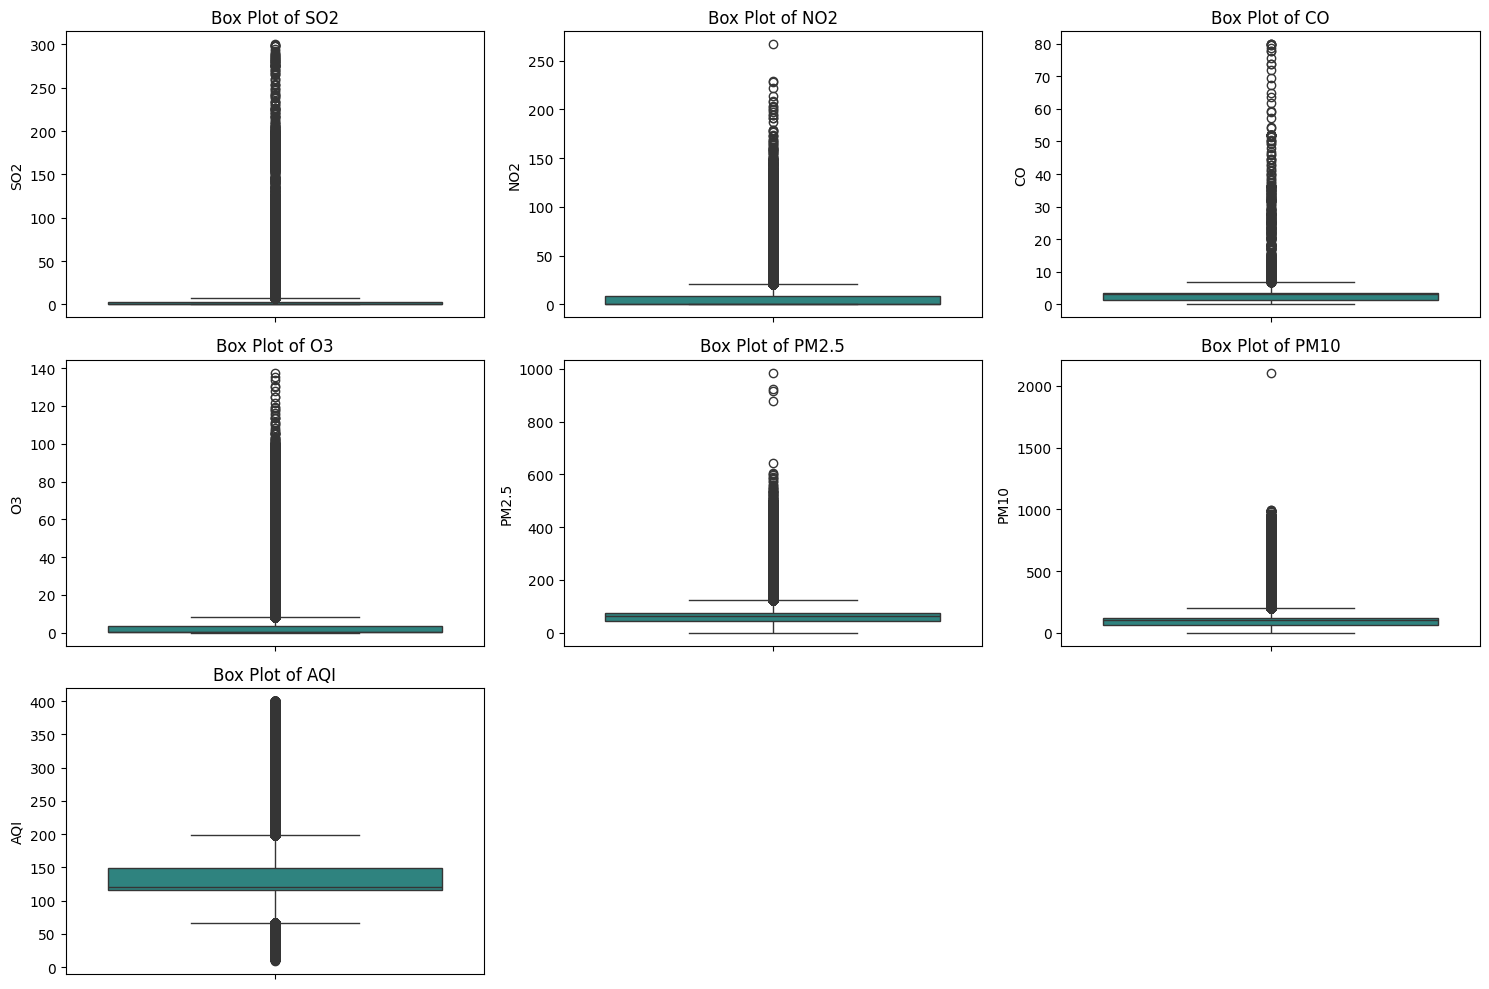

In [ ]:
# Create box plots for numerical columns
plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_cols):
    plt.subplot(3, 3, i + 1)
    sns.boxplot(y=df[col], palette='viridis')
    plt.title(f'Box Plot of {col}')
    plt.ylabel(col)

plt.tight_layout()
plt.show()

/tmp/ipykernel_44212/462093035.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='AQI_Category', y='AQI', order=df['AQI_Category'].value_counts().index, palette='viridis')


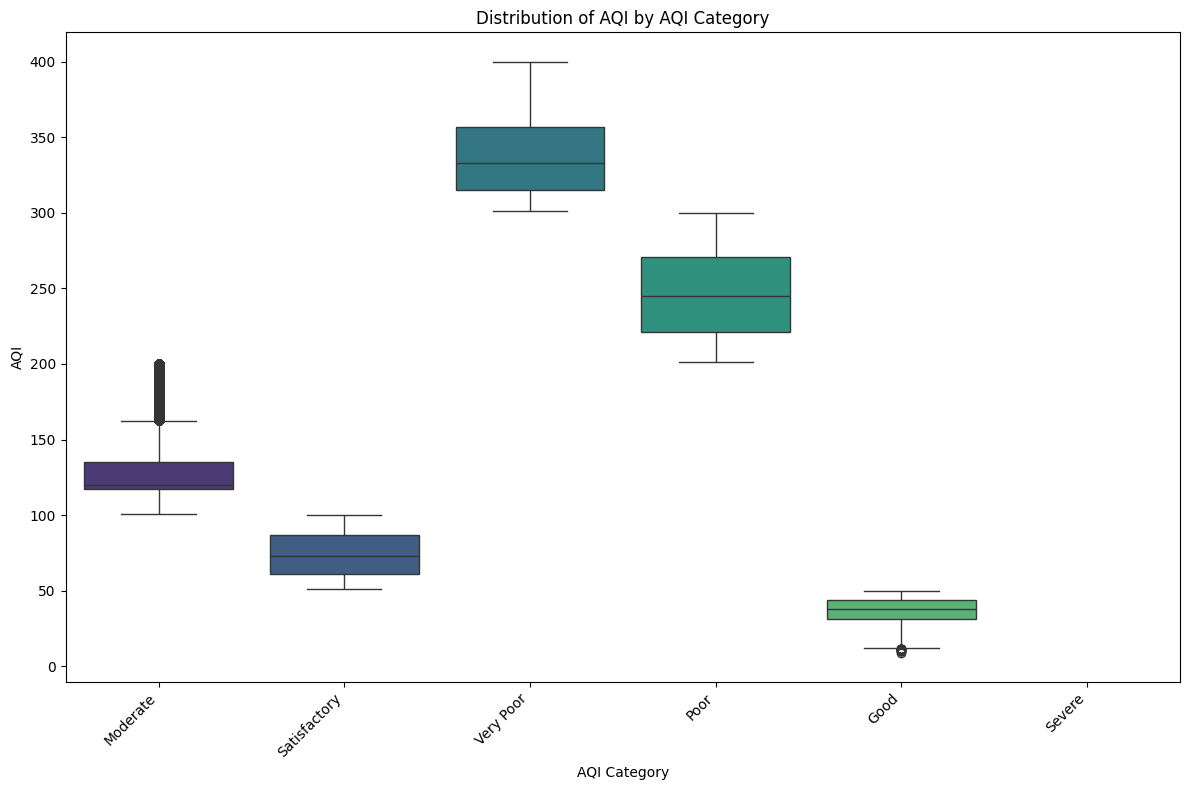

In [ ]:
# Create a box plot to show the distribution of AQI across different AQI_Category values
plt.figure(figsize=(12, 8))
sns.boxplot(data=df, x='AQI_Category', y='AQI', order=df['AQI_Category'].value_counts().index, palette='viridis')
plt.title('Distribution of AQI by AQI Category')
plt.xlabel('AQI Category')
plt.ylabel('AQI')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## Explore relationships

### Subtask:
Investigate relationships between different variables using scatter plots, correlation matrices, or other appropriate visualizations.


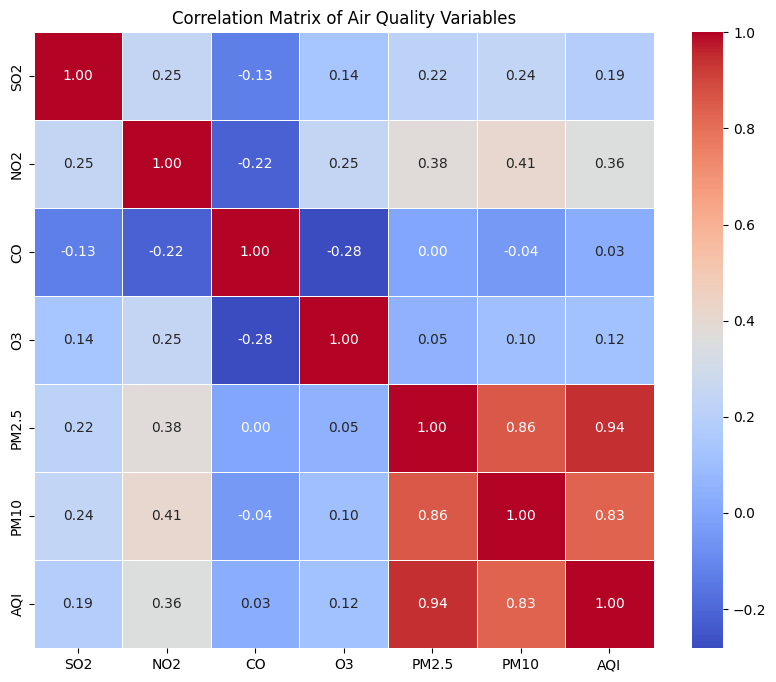

In [ ]:
# Select numerical columns for correlation analysis
numerical_cols = ['SO2', 'NO2', 'CO', 'O3', 'PM2.5', 'PM10', 'AQI']
df_numerical = df[numerical_cols]

# Calculate the correlation matrix
correlation_matrix = df_numerical.corr()

# Visualize the correlation matrix using a heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Matrix of Air Quality Variables')
plt.show()

**Reasoning**:
Generate scatter plots for pairs of numerical variables that show significant correlations based on the heatmap and add titles and labels.



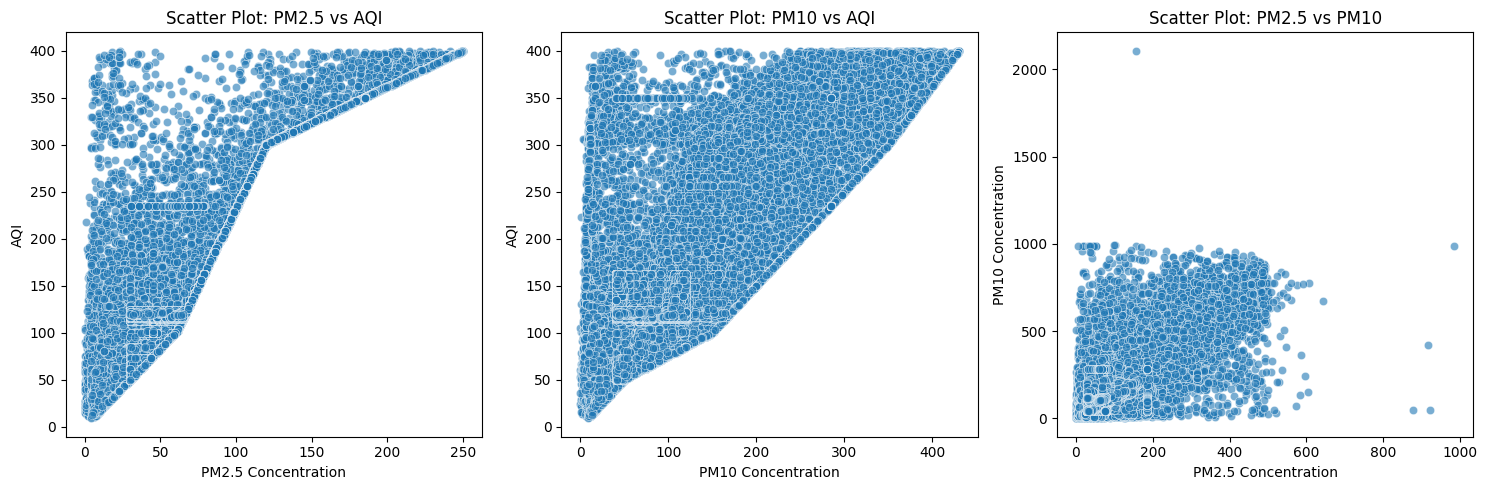

In [ ]:
# Generate scatter plots for pairs with significant correlations (based on the heatmap)
# Example pairs with relatively strong correlations: PM2.5 vs AQI, PM10 vs AQI, PM2.5 vs PM10

plt.figure(figsize=(15, 5))

# Scatter plot for PM2.5 vs AQI
plt.subplot(1, 3, 1)
sns.scatterplot(data=df, x='PM2.5', y='AQI', alpha=0.6)
plt.title('Scatter Plot: PM2.5 vs AQI')
plt.xlabel('PM2.5 Concentration')
plt.ylabel('AQI')

# Scatter plot for PM10 vs AQI
plt.subplot(1, 3, 2)
sns.scatterplot(data=df, x='PM10', y='AQI', alpha=0.6)
plt.title('Scatter Plot: PM10 vs AQI')
plt.xlabel('PM10 Concentration')
plt.ylabel('AQI')

# Scatter plot for PM2.5 vs PM10
plt.subplot(1, 3, 3)
sns.scatterplot(data=df, x='PM2.5', y='PM10', alpha=0.6)
plt.title('Scatter Plot: PM2.5 vs PM10')
plt.xlabel('PM2.5 Concentration')
plt.ylabel('PM10 Concentration')


plt.tight_layout()
plt.show()

## Analyze by location (optional but relevant to previous discussion)



In [ ]:
# Define the numerical columns
numerical_cols = ['SO2', 'NO2', 'CO', 'O3', 'PM2.5', 'PM10', 'AQI']

# Group by 'Location' and calculate the mean for numerical columns
location_avg_pollution = df.groupby('Location')[numerical_cols].mean()

# Display the resulting DataFrame
print("Average pollution levels and AQI across different locations:")
display(location_avg_pollution)

Average pollution levels and AQI across different locations:


,SO2,NO2,CO,O3,PM2.5,PM10,AQI
Location,,,,,,,
Agrabad Chittagong,5.962294,11.220125,1.501153,10.540519,84.603683,149.233053,163.788023
BARC,5.339313,25.881212,1.522582,12.296675,92.084094,139.822779,183.253308
Barishal,17.096135,4.911627,1.170971,10.726102,97.676070,142.828860,179.729426
Cumilla,0.911429,0.045714,4.363571,0.590714,131.235714,134.992857,260.769231
Darussalam,8.688735,17.020651,2.193969,4.996889,101.956771,170.668067,176.367703
Gazipur,8.673964,9.319248,1.858797,6.923380,128.757902,207.859167,213.986170
Khulna,2.554788,19.765891,1.392481,8.708130,59.234927,115.033119,125.247788
"Kuril Bishow Road, Dhaka, Bangladesh",0.040080,0.065992,3.340622,0.254754,60.933063,89.673654,125.627886
Mymansingh,1.968936,20.686875,0.942078,11.425726,167.416892,251.632095,303.804688


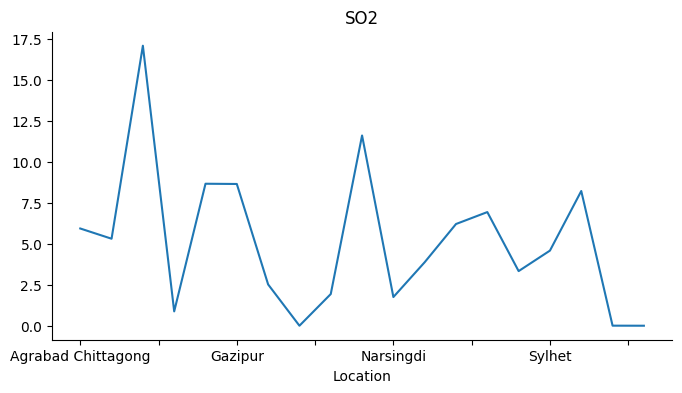

In [ ]:
# @title SO2

from matplotlib import pyplot as plt
location_avg_pollution['SO2'].plot(kind='line', figsize=(8, 4), title='SO2')
plt.gca().spines[['top', 'right']].set_visible(False)

/tmp/ipykernel_44212/3280124623.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=location_avg_pollution_sorted.index, y=location_avg_pollution_sorted['AQI'], palette='viridis')


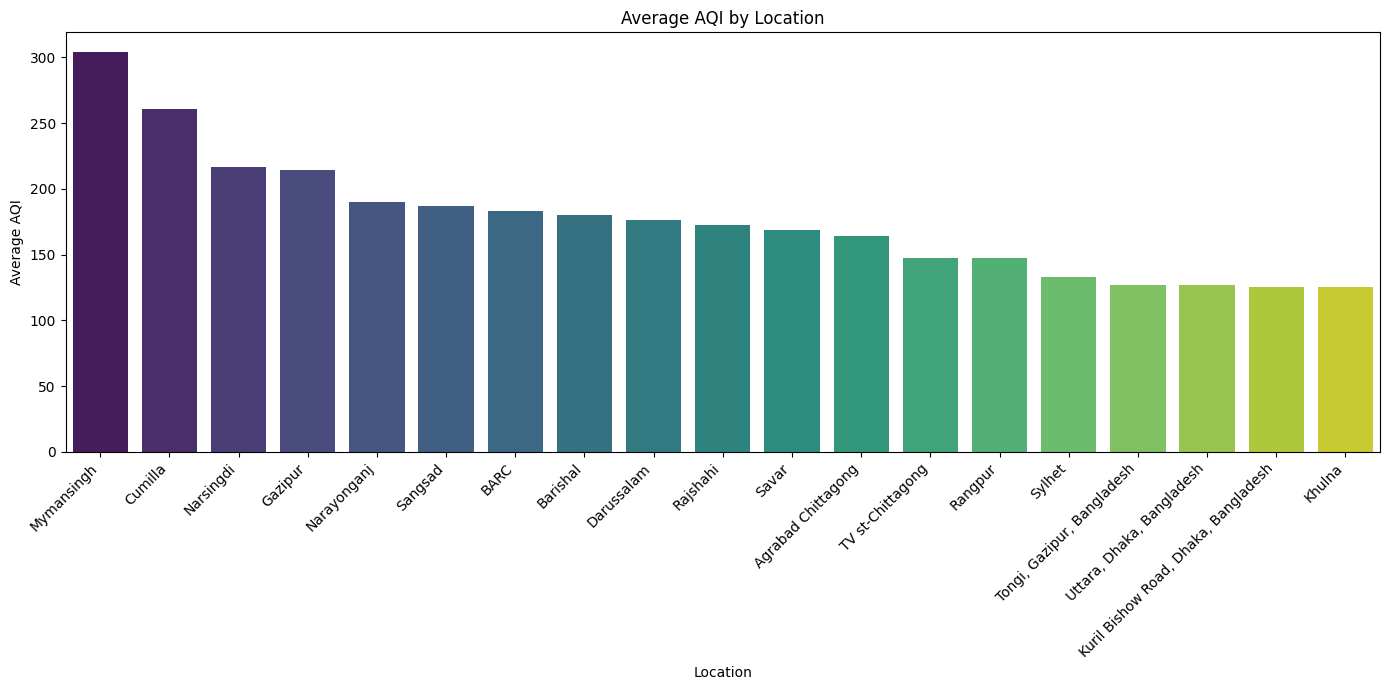

In [ ]:
# Sort locations by average AQI for better visualization
location_avg_pollution_sorted = location_avg_pollution.sort_values('AQI', ascending=False)

# Create a bar plot for average AQI per location
plt.figure(figsize=(14, 7))
sns.barplot(x=location_avg_pollution_sorted.index, y=location_avg_pollution_sorted['AQI'], palette='viridis')
plt.title('Average AQI by Location')
plt.xlabel('Location')
plt.ylabel('Average AQI')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

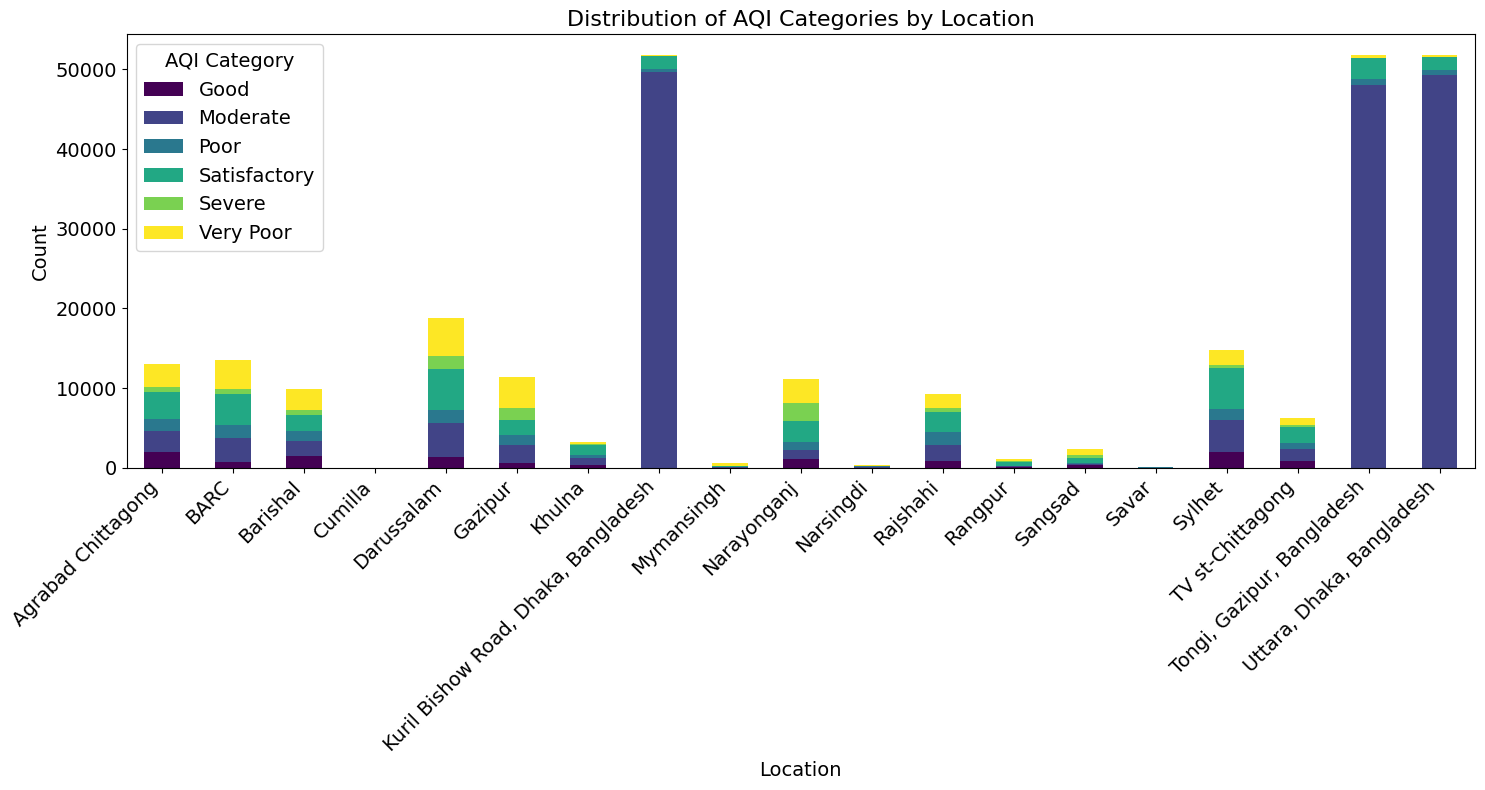

In [ ]:
# Group by 'Location' and 'AQI_Category' and count occurrences
location_aqi_category_counts = df.groupby(['Location', 'AQI_Category']).size().unstack(fill_value=0)

# Plot the stacked bar chart for AQI category distribution by location
plt.figure(figsize=(15, 8))
ax = location_aqi_category_counts.plot(kind='bar', stacked=True, colormap='viridis', ax=plt.gca())
plt.title('Distribution of AQI Categories by Location', fontsize=16)
plt.xlabel('Location', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.xticks(rotation=45, ha='right', fontsize=14)
plt.yticks(fontsize=14)
plt.legend(title='AQI Category', loc='upper left', fontsize=14, title_fontsize=14)
plt.tight_layout()

# Remove value counts on the bars
# for container in ax.containers:
#     ax.bar_label(container, label_type='center')

plt.show()

## Analyze temporal patterns (optional as you have date/time data)

### Subtask:
Investigate trends or patterns over time for relevant variables.


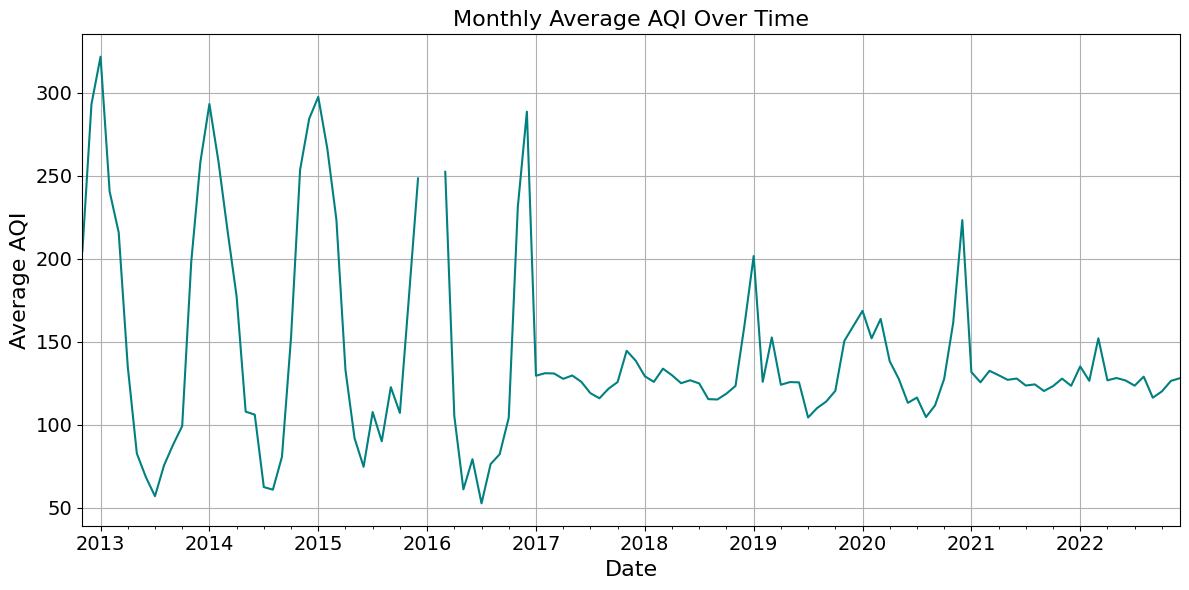

In [ ]:
# Convert 'Date' column to datetime and set it as index if it's not already
import pandas as pd
import matplotlib.pyplot as plt

if not isinstance(df.index, pd.DatetimeIndex):
    df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
    df.set_index('Date', inplace=True)
    df.sort_index(inplace=True)

# Resample the DataFrame to a monthly frequency, calculating the mean for 'AQI'
# Using 'ME' instead of 'M' as 'M' is deprecated and 'ME' denotes Month End frequency
monthly_avg_aqi = df['AQI'].resample('ME').mean()

# Create a line plot to visualize the monthly average AQI over time
plt.figure(figsize=(12, 6))
monthly_avg_aqi.plot(kind='line', color='teal')
plt.title('Monthly Average AQI Over Time', fontsize=16)
plt.xlabel('Date', fontsize=16)
plt.ylabel('Average AQI', fontsize=16)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.grid(True)
plt.tight_layout()
plt.show()

/tmp/ipykernel_44212/1801976157.py:3: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_avg_pollutants = df[pollutant_cols].resample('M').mean()


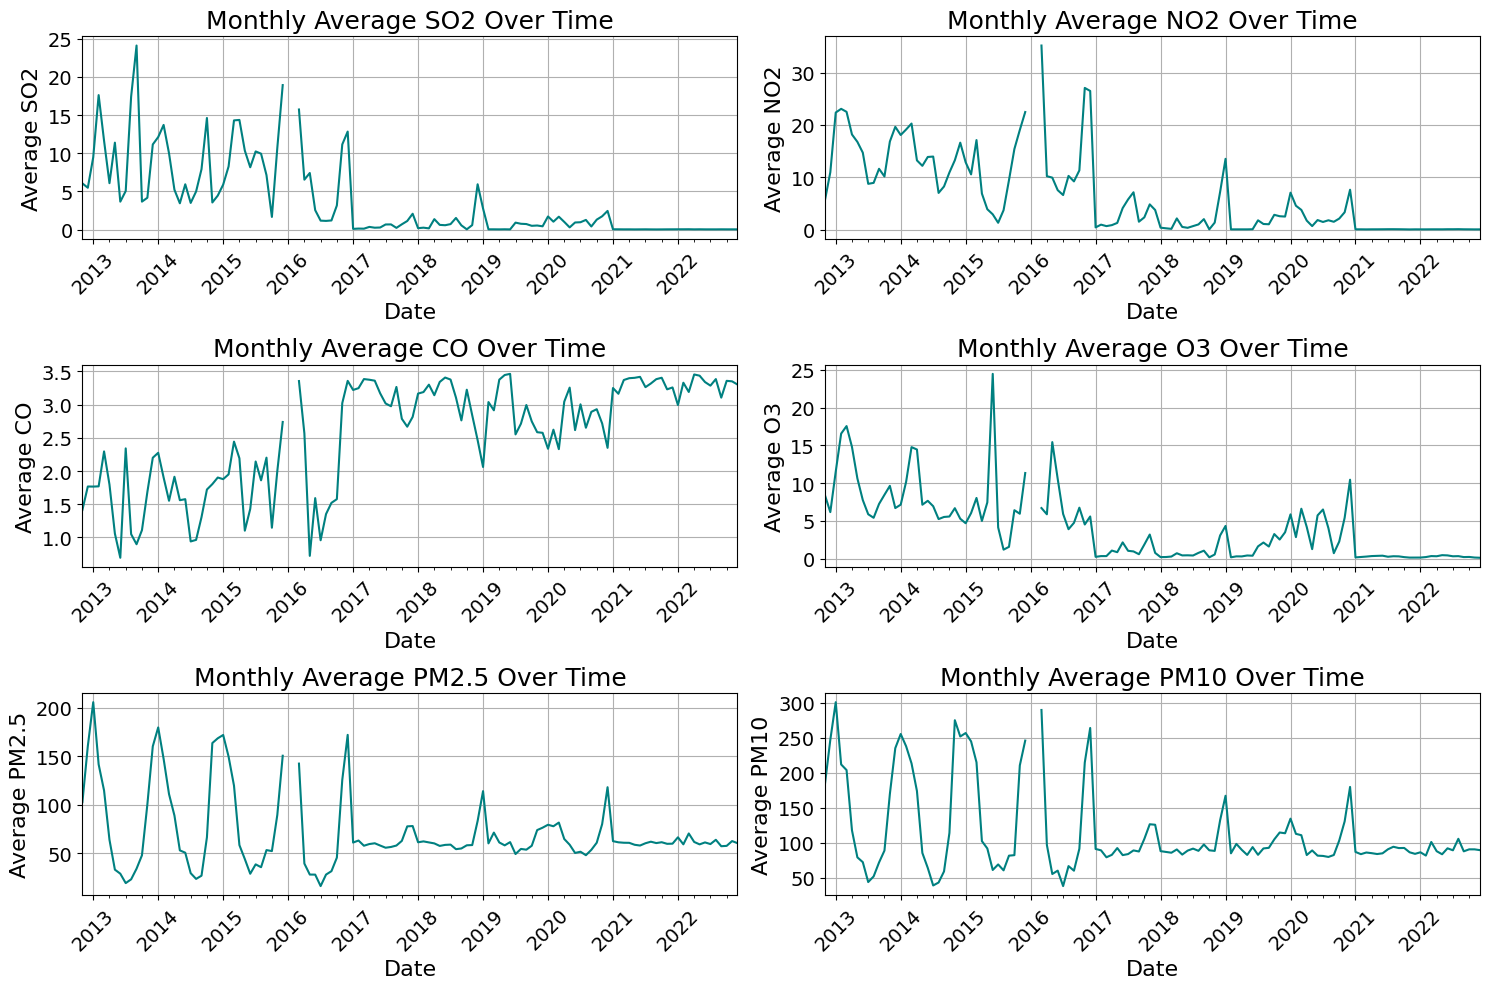

In [ ]:
# Resample the DataFrame to a monthly frequency, calculating the mean for numerical pollutants
pollutant_cols = ['SO2', 'NO2', 'CO', 'O3', 'PM2.5', 'PM10']
monthly_avg_pollutants = df[pollutant_cols].resample('M').mean()

# Create line plots to visualize the monthly average of each pollutant over time
plt.figure(figsize=(15, 10))

for i, col in enumerate(pollutant_cols):
    plt.subplot(3, 2, i + 1)
    monthly_avg_pollutants[col].plot(kind='line', color='teal')
    plt.title(f'Monthly Average {col} Over Time', fontsize=18)
    plt.xlabel('Date', fontsize=16)
    plt.ylabel(f'Average {col}',  fontsize=16)
    plt.xticks(rotation=45,fontsize=14)
    plt.yticks(fontsize=14)
    plt.grid(True)

plt.tight_layout()
plt.show()

# Task
Analyze hourly patterns of pollutants and plot the monthly average pollutants.

## Extract hour

### Subtask:
Extract the hour from the 'Time' column.


In [ ]:
# Convert 'Time' column to datetime objects, coercing errors
df['Time'] = pd.to_datetime(df['Time'], errors='coerce').dt.time


df['Hour'] = df['Time'].apply(lambda x: x.hour if pd.notna(x) else None)

# Display the first few rows with the new 'Hour' column
display(df.head())

/tmp/ipykernel_44212/2948849963.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Time'] = pd.to_datetime(df['Time'], errors='coerce').dt.time


,Time,Location,PM2.5,PM10,NO2,O3,CO,SO2,AQI,AQI_Category,Hour
Date,,,,,,,,,,,
2012-11-01,06:00:00,Narayonganj,103.89,114.84,0.03,0.84,0.80,5.95,245.0,Poor,6.0
2012-11-01,15:00:00,Narayonganj,69.03,124.54,0.03,1.07,0.44,4.87,128.0,Moderate,15.0
2012-11-01,14:00:00,Narayonganj,65.13,127.88,0.04,1.01,0.40,4.72,115.0,Moderate,14.0
2012-11-01,13:00:00,Narayonganj,62.09,124.16,1.08,1.28,0.39,4.86,105.0,Moderate,13.0
2012-11-01,12:00:00,Narayonganj,62.00,105.80,2.75,1.99,0.46,5.01,104.0,Moderate,12.0


## Group by hour

### Subtask:
Group the DataFrame by the extracted hour.


In [ ]:
# Define the numerical columns to analyze
numerical_cols = ['SO2', 'NO2', 'CO', 'O3', 'PM2.5', 'PM10', 'AQI']

# Group by the 'Hour' column and calculate the mean for numerical columns
hourly_grouped_data = df.groupby('Hour')[numerical_cols].mean()

# Display the resulting DataFrame
print("Average pollution levels and AQI across different hours:")
display(hourly_grouped_data)

Average pollution levels and AQI across different hours:


,SO2,NO2,CO,O3,PM2.5,PM10,AQI
Hour,,,,,,,
0.0,0.503799,0.197197,3.171340,0.225698,59.609494,90.008110,124.993491
1.0,3.652657,6.955308,2.628715,2.621447,84.514758,134.611878,154.422751
2.0,3.562077,6.232812,2.590049,2.637770,82.202332,127.273981,152.056471
3.0,3.399700,5.819817,2.565032,2.598090,80.541556,122.379906,151.224026
4.0,3.286371,5.435186,2.555157,2.605868,78.334116,117.033374,149.326712
5.0,3.308561,5.149426,2.548600,2.475122,77.025242,114.240861,147.573251
6.0,3.275081,5.146185,2.540079,2.458716,75.680295,110.802729,146.712209
7.0,3.431248,5.435017,2.532862,2.589283,76.100534,111.482763,147.787890
8.0,3.637732,6.076328,2.534154,3.040053,78.831615,116.208745,150.363057


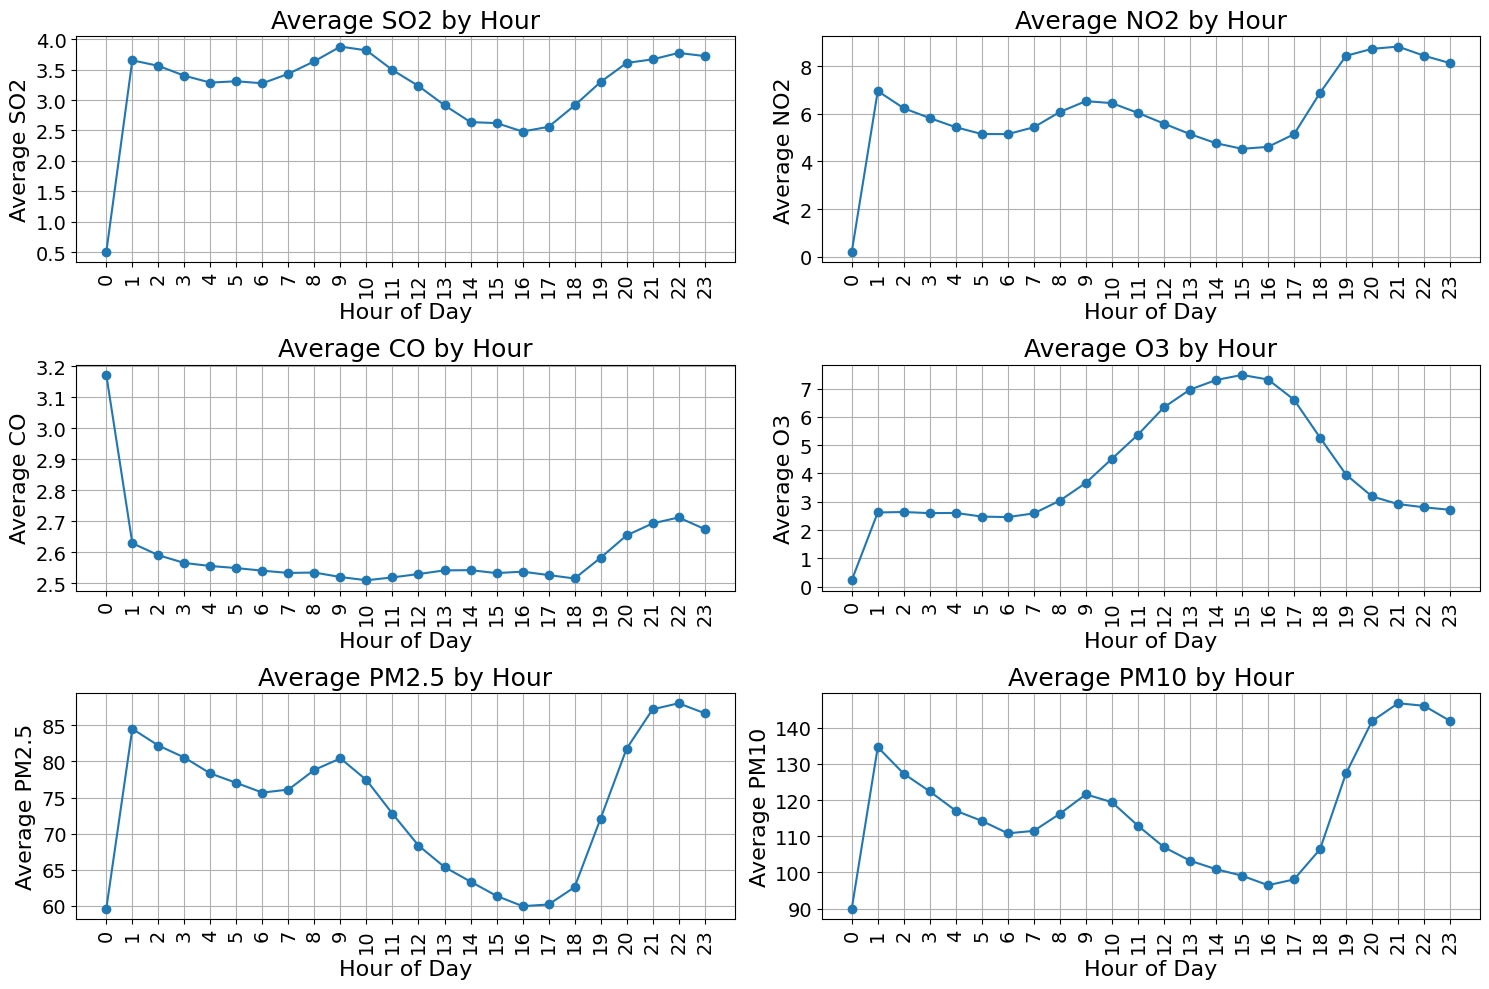

In [ ]:
# Create line plots to visualize the average of each pollutant over the 24 hours
plt.figure(figsize=(15, 10))

pollutant_cols = ['SO2', 'NO2', 'CO', 'O3', 'PM2.5', 'PM10']

for i, col in enumerate(pollutant_cols):
    plt.subplot(3, 2, i + 1)
    hourly_grouped_data[col].plot(kind='line', marker='o', linestyle='-')
    plt.title(f'Average {col} by Hour',  fontsize=18)
    plt.xlabel('Hour of Day',  fontsize=16)
    plt.ylabel(f'Average {col}',  fontsize=16)
    plt.xticks( rotation=90,fontsize=14)
    plt.yticks(fontsize=14)
    plt.grid(True)
    plt.xticks(range(0, 24))

plt.tight_layout()
plt.show()

## Calculate hourly averages

### Subtask:
Calculate the mean of numerical columns for each hour.


In [ ]:
# Define the numerical columns
numerical_cols = ['SO2', 'NO2', 'CO', 'O3', 'PM2.5', 'PM10', 'AQI']

# Group by the 'Hour' column and calculate the mean for numerical columns
hourly_grouped_data = df.groupby('Hour')[numerical_cols].mean()

# Display the resulting DataFrame
print("Average pollution levels and AQI across different hours:")
display(hourly_grouped_data)

Average pollution levels and AQI across different hours:


,SO2,NO2,CO,O3,PM2.5,PM10,AQI
Hour,,,,,,,
0.0,0.503799,0.197197,3.171340,0.225698,59.609494,90.008110,124.993491
1.0,3.652657,6.955308,2.628715,2.621447,84.514758,134.611878,154.422751
2.0,3.562077,6.232812,2.590049,2.637770,82.202332,127.273981,152.056471
3.0,3.399700,5.819817,2.565032,2.598090,80.541556,122.379906,151.224026
4.0,3.286371,5.435186,2.555157,2.605868,78.334116,117.033374,149.326712
5.0,3.308561,5.149426,2.548600,2.475122,77.025242,114.240861,147.573251
6.0,3.275081,5.146185,2.540079,2.458716,75.680295,110.802729,146.712209
7.0,3.431248,5.435017,2.532862,2.589283,76.100534,111.482763,147.787890
8.0,3.637732,6.076328,2.534154,3.040053,78.831615,116.208745,150.363057


## Visualize hourly patterns

### Subtask:
Create plots to visualize the hourly average of key variables.


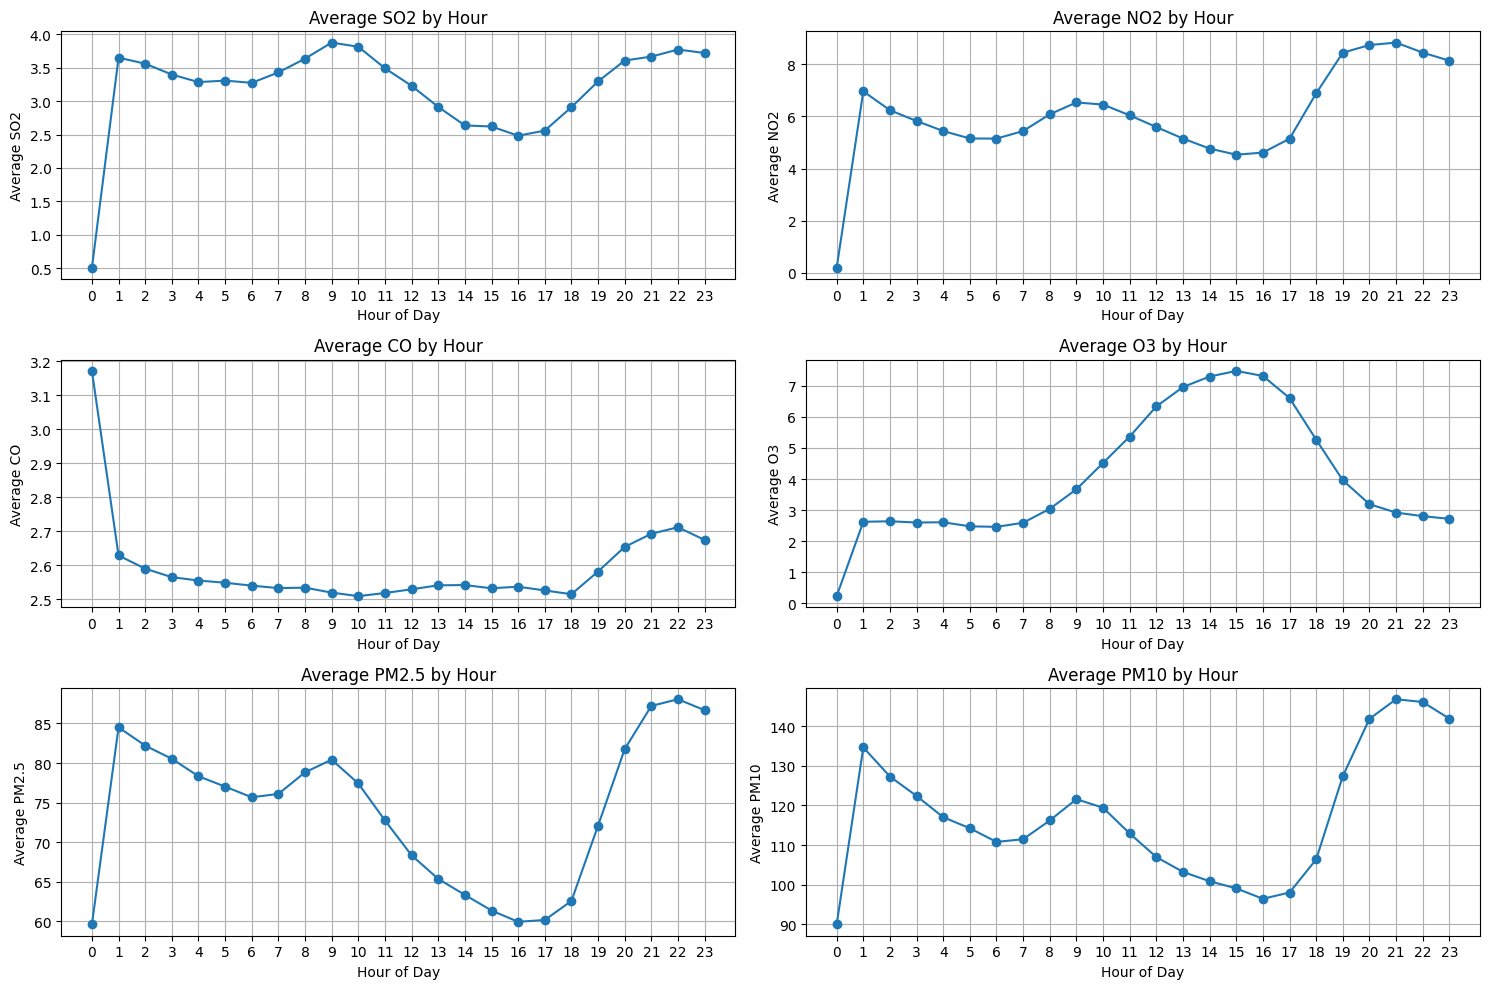

In [ ]:
# Create line plots to visualize the average of each pollutant over the 24 hours
plt.figure(figsize=(15, 10))

pollutant_cols = ['SO2', 'NO2', 'CO', 'O3', 'PM2.5', 'PM10']

for i, col in enumerate(pollutant_cols):
    plt.subplot(3, 2, i + 1)
    hourly_grouped_data[col].plot(kind='line', marker='o', linestyle='-')
    plt.title(f'Average {col} by Hour')
    plt.xlabel('Hour of Day')
    plt.ylabel(f'Average {col}')
    plt.grid(True)
    plt.xticks(range(0, 24))

plt.tight_layout()
plt.show()

# Task
Analyze and visualize monthly and seasonal patterns of pollutants and other relevant variables from the dataset.

## Extract month and year

### Subtask:
Extract the month and year from the 'Date' column.


In [ ]:
# Extract the month from the 'Date' index and store it in a new 'Month' column
df['Month'] = df.index.month

# Extract the year from the 'Date' index and store it in a new 'Year' column
df['Year'] = df.index.year

# Display the first few rows of the DataFrame with the new columns
display(df.head())

,Time,Location,PM2.5,PM10,NO2,O3,CO,SO2,AQI,AQI_Category,Hour,Month,Year
Date,,,,,,,,,,,,,
2012-11-01,06:00:00,Narayonganj,103.89,114.84,0.03,0.84,0.80,5.95,245.0,Poor,6.0,11.0,2012.0
2012-11-01,15:00:00,Narayonganj,69.03,124.54,0.03,1.07,0.44,4.87,128.0,Moderate,15.0,11.0,2012.0
2012-11-01,14:00:00,Narayonganj,65.13,127.88,0.04,1.01,0.40,4.72,115.0,Moderate,14.0,11.0,2012.0
2012-11-01,13:00:00,Narayonganj,62.09,124.16,1.08,1.28,0.39,4.86,105.0,Moderate,13.0,11.0,2012.0
2012-11-01,12:00:00,Narayonganj,62.00,105.80,2.75,1.99,0.46,5.01,104.0,Moderate,12.0,11.0,2012.0


## Group by month

### Subtask:
Group the DataFrame by month and calculate the mean of numerical columns.


In [ ]:
# Define the numerical columns to analyze
numerical_cols = ['SO2', 'NO2', 'CO', 'O3', 'PM2.5', 'PM10', 'AQI']

# Group by the 'Month' column and calculate the mean for numerical columns
monthly_grouped_data = df.groupby('Month')[numerical_cols].mean()

# Display the resulting DataFrame
print("Average pollution levels and AQI across different months:")
display(monthly_grouped_data)

Average pollution levels and AQI across different months:


,SO2,NO2,CO,O3,PM2.5,PM10,AQI
Month,,,,,,,
1.0,3.799072,9.451042,2.446507,4.382800,115.171431,169.901142,198.647378
2.0,5.820836,8.217946,2.591000,5.279279,96.625438,145.039090,175.826548
3.0,4.476880,8.167472,2.691988,6.382912,84.950141,135.884403,169.768278
4.0,2.490653,5.082563,2.873444,4.776140,63.962186,100.486726,134.549978
5.0,2.702593,4.113824,2.739764,3.274283,53.272499,84.289931,116.045536
6.0,1.762693,5.497923,2.450446,4.169503,49.941351,80.527624,108.809182
7.0,1.624182,3.995163,2.707212,3.047991,46.292555,74.163837,101.710659
8.0,3.168511,3.499384,2.534693,2.371726,48.510168,81.431132,105.025228
9.0,3.606354,3.295961,2.639602,1.854311,51.615901,85.426176,110.911431


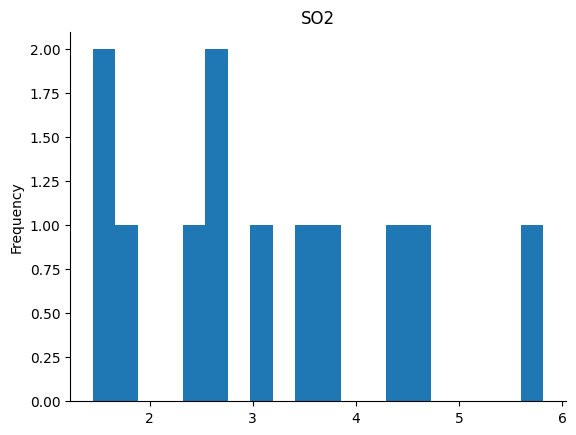

In [ ]:
# @title SO2

from matplotlib import pyplot as plt
monthly_grouped_data['SO2'].plot(kind='hist', bins=20, title='SO2')
plt.gca().spines[['top', 'right',]].set_visible(False)

## Visualize monthly patterns

### Subtask:
Create plots to visualize the monthly average of key variables.


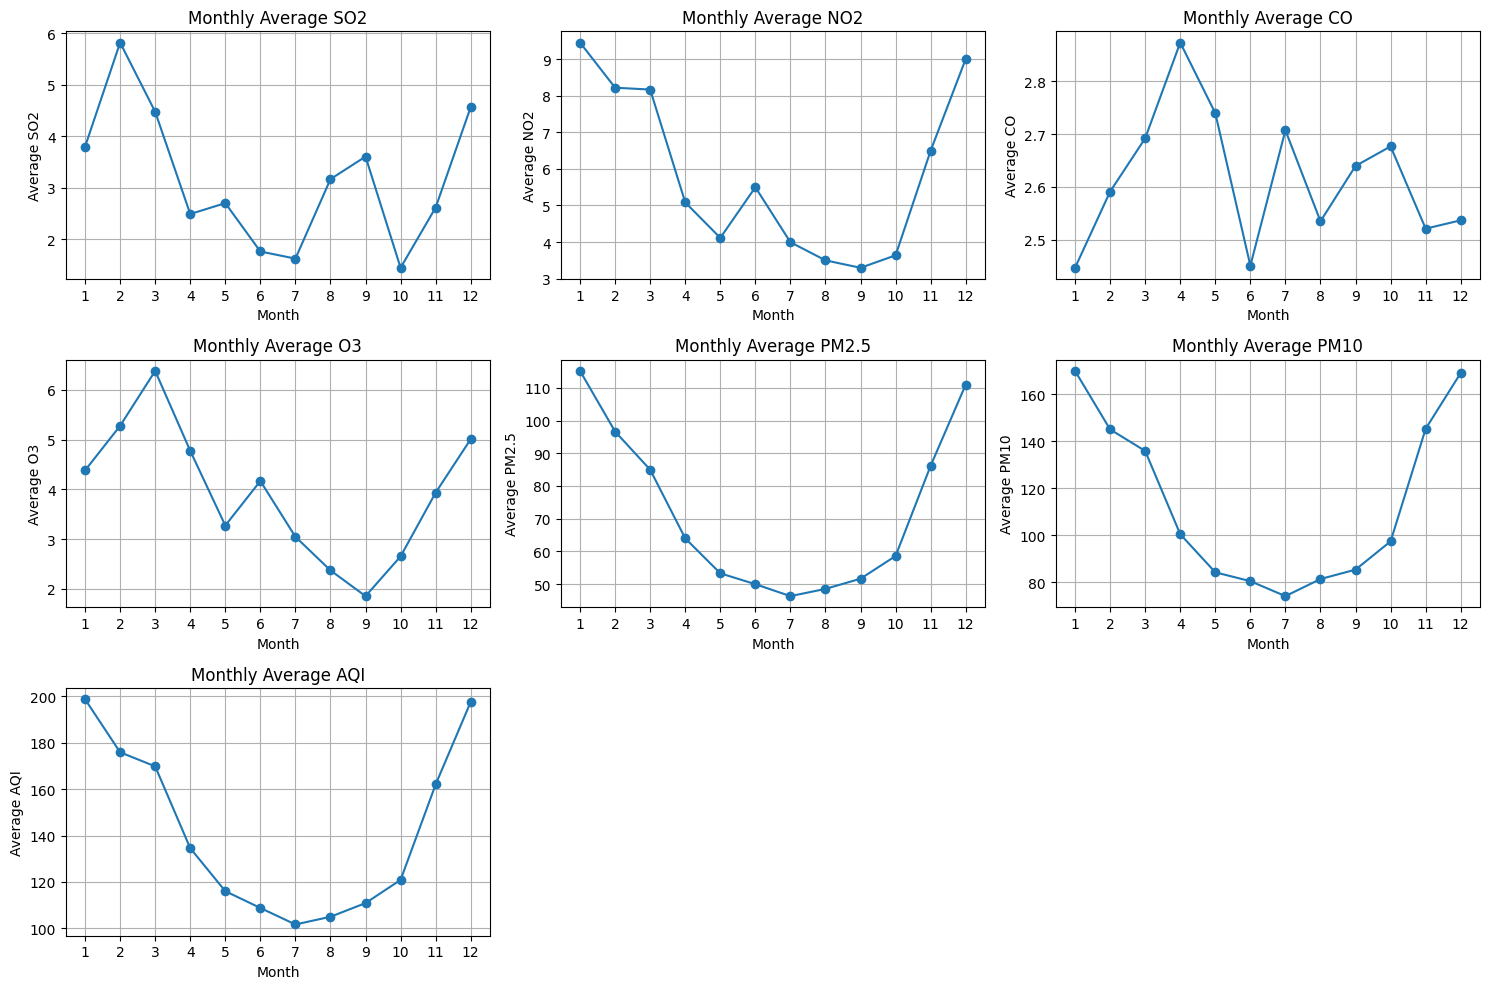

In [ ]:
# Select the numerical columns from the monthly_grouped_data DataFrame
monthly_avg_numerical = monthly_grouped_data[['SO2', 'NO2', 'CO', 'O3', 'PM2.5', 'PM10', 'AQI']]

# Create line plots to visualize the monthly average of each pollutant and AQI over time
plt.figure(figsize=(15, 10))

for i, col in enumerate(monthly_avg_numerical.columns):
    plt.subplot(3, 3, i + 1)
    monthly_avg_numerical[col].plot(kind='line', marker='o', linestyle='-')
    plt.title(f'Monthly Average {col}')
    plt.xlabel('Month')
    plt.ylabel(f'Average {col}')
    plt.grid(True)
    plt.xticks(range(1, 13)) # Set x-axis ticks for each month (1-12)


plt.tight_layout()
plt.show()

## Group by season

### Subtask:
Define seasons and group the DataFrame by season, calculating the mean of numerical columns.


In [ ]:
# Define a function to map months to seasons
def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    elif month in [9, 10, 11]:
        return 'Autumn'
    return None

# Apply the function to create a 'Season' column
df['Season'] = df['Month'].apply(get_season)

# Define the numerical columns to analyze
numerical_cols = ['SO2', 'NO2', 'CO', 'O3', 'PM2.5', 'PM10', 'AQI']

# Group by the 'Season' column and calculate the mean for numerical columns
seasonal_grouped_data = df.groupby('Season')[numerical_cols].mean()

# Display the resulting DataFrame
print("Average pollution levels and AQI across different seasons:")
display(seasonal_grouped_data)

Average pollution levels and AQI across different seasons:


,SO2,NO2,CO,O3,PM2.5,PM10,AQI
Season,,,,,,,
Autumn,2.542491,4.618588,2.606329,2.898179,66.941885,111.963385,132.932078
Spring,3.248624,5.849843,2.768089,4.860768,67.887607,107.685929,140.620801
Summer,2.181531,4.337000,2.563735,3.201819,48.254055,78.709137,105.199624
Winter,4.654023,8.937429,2.520638,4.868937,108.394574,162.582543,191.656197


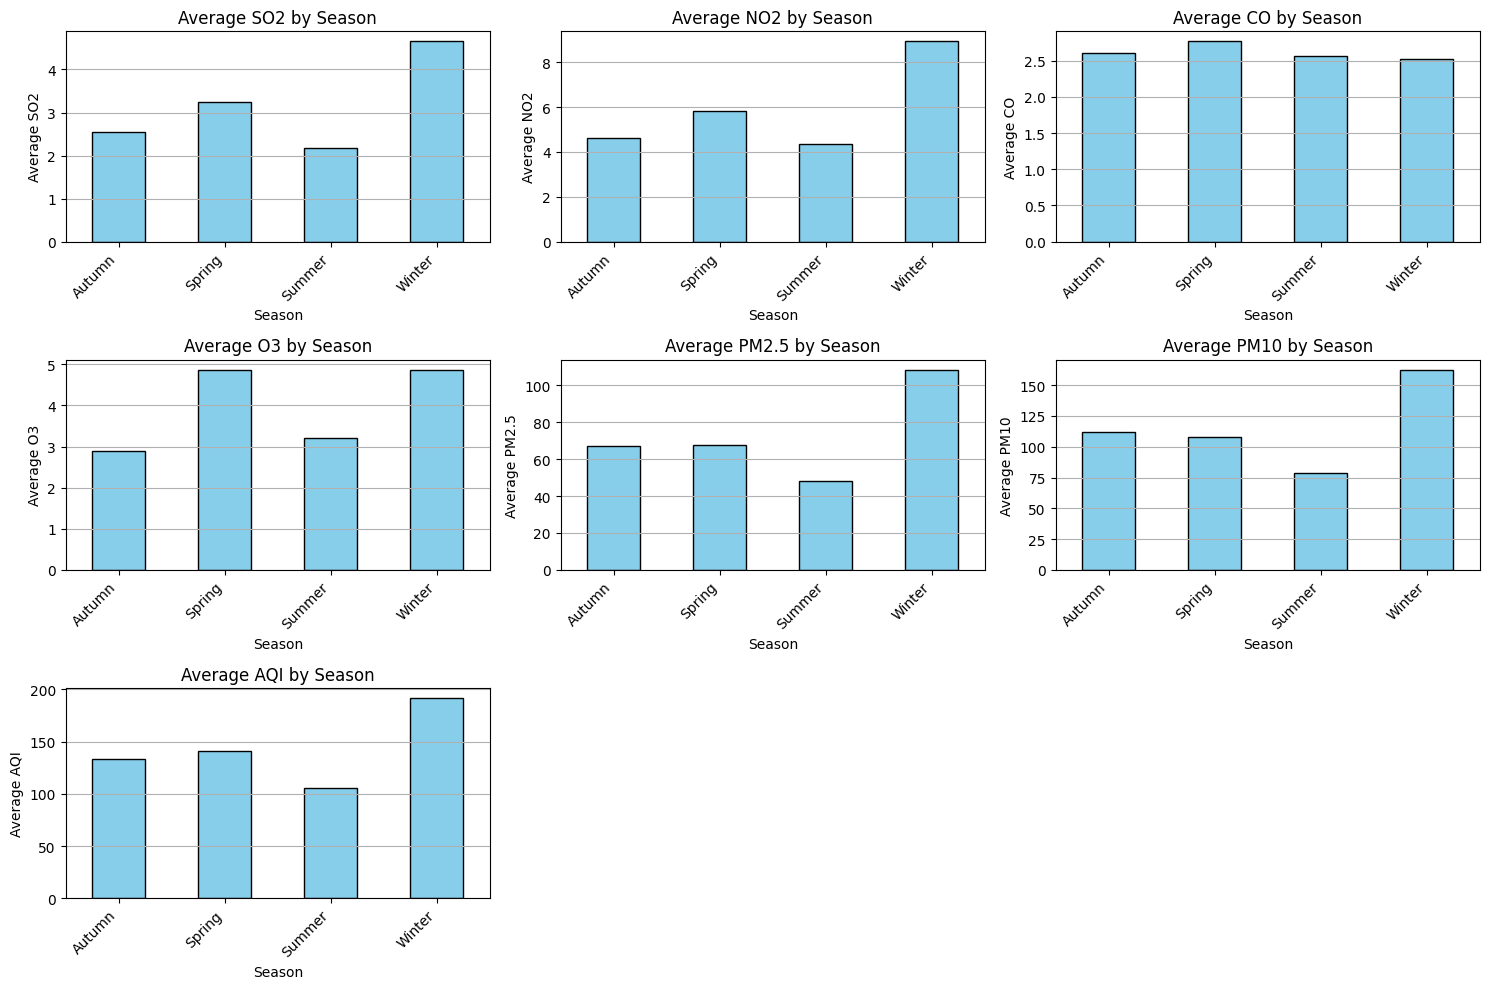

In [ ]:
# Create bar plots to visualize the average of each pollutant and AQI across seasons
plt.figure(figsize=(15, 10))

numerical_cols = ['SO2', 'NO2', 'CO', 'O3', 'PM2.5', 'PM10', 'AQI']

for i, col in enumerate(numerical_cols):
    plt.subplot(3, 3, i + 1)
    seasonal_grouped_data[col].plot(kind='bar', color='skyblue', edgecolor='black')
    plt.title(f'Average {col} by Season')
    plt.xlabel('Season')
    plt.ylabel(f'Average {col}')
    plt.xticks(rotation=45, ha='right')
    plt.grid(axis='y')

plt.tight_layout()
plt.show()

## Visualize seasonal patterns

### Subtask:
Create plots to visualize the average of key variables by season.


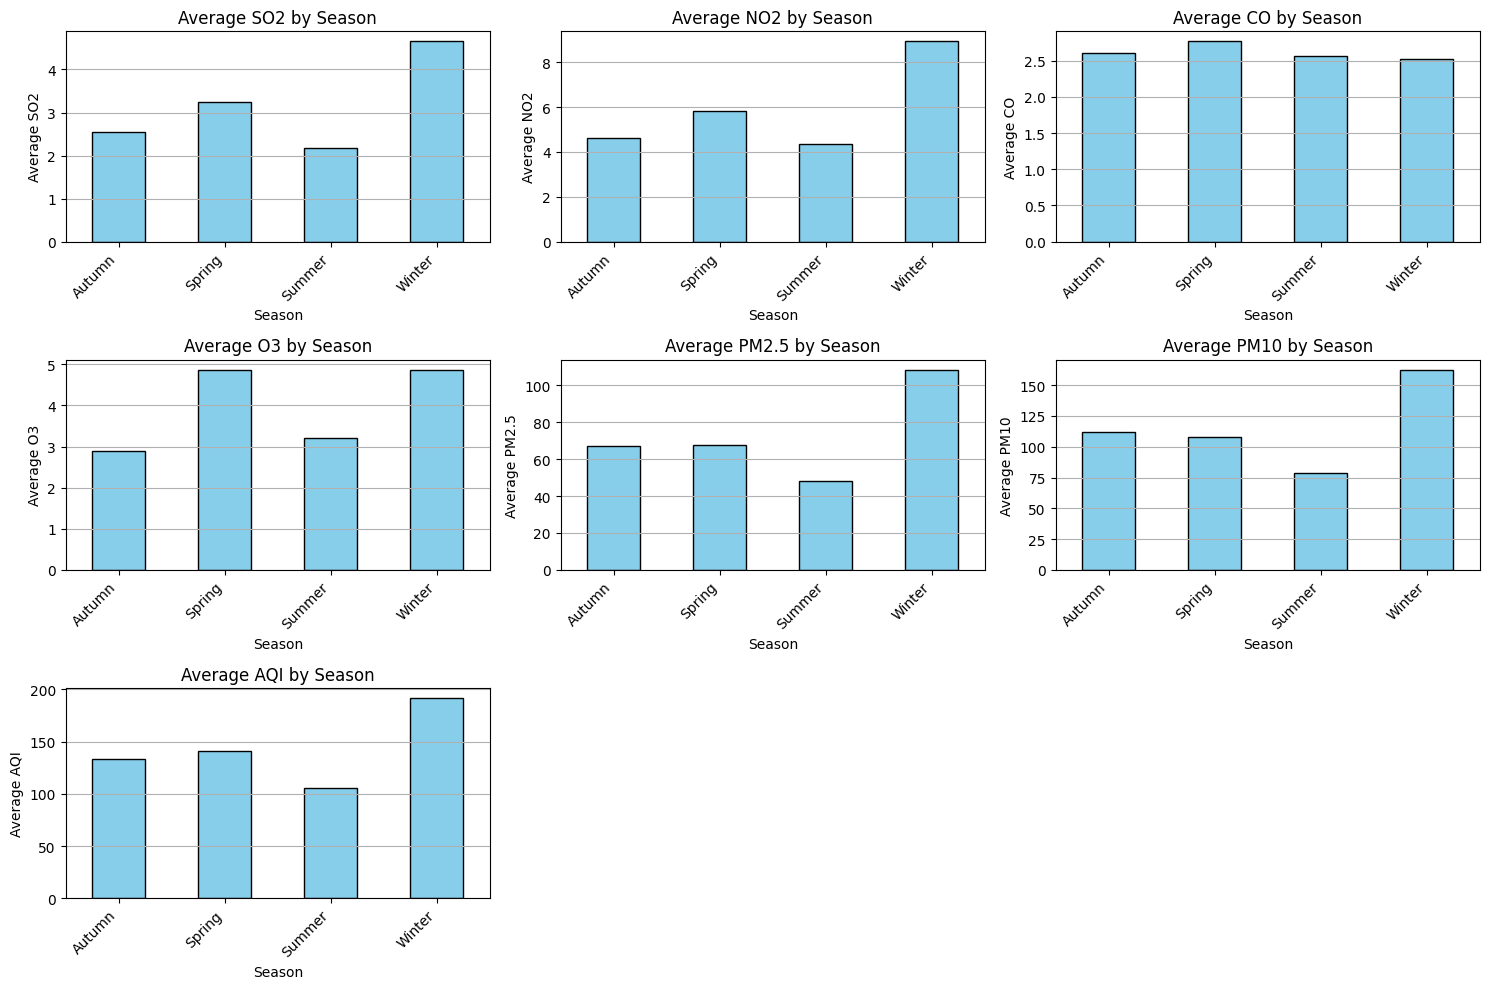

In [ ]:
# Create bar plots to visualize the average of each pollutant and AQI across seasons
plt.figure(figsize=(15, 10))

numerical_cols = ['SO2', 'NO2', 'CO', 'O3', 'PM2.5', 'PM10', 'AQI']

for i, col in enumerate(numerical_cols):
    plt.subplot(3, 3, i + 1)
    seasonal_grouped_data[col].plot(kind='bar', color='skyblue', edgecolor='black')
    plt.title(f'Average {col} by Season')
    plt.xlabel('Season')
    plt.ylabel(f'Average {col}')
    plt.xticks(rotation=45, ha='right')
    plt.grid(axis='y')

plt.tight_layout()
plt.show()

# Task
Analyze the provided time series data to identify and visualize temporal patterns, including trends, seasonality, and relationships with time components.

## Prepare time series data

### Subtask:
Ensure the 'Date' column is in datetime format and set as the index.


In [ ]:
# The 'Date' column is already the index. Ensure it is in datetime format.
# The index is already of datetime dtype based on the previous successful execution.
# No action is needed to convert or set the index again.

# Display the first few rows of the DataFrame to verify the index
display(df.head())

,Time,Location,PM2.5,PM10,NO2,O3,CO,SO2,AQI,AQI_Category,Hour,Month,Year,Season
Date,,,,,,,,,,,,,,
2012-11-01,06:00:00,Narayonganj,103.89,114.84,0.03,0.84,0.80,5.95,245.0,Poor,6.0,11.0,2012.0,Autumn
2012-11-01,15:00:00,Narayonganj,69.03,124.54,0.03,1.07,0.44,4.87,128.0,Moderate,15.0,11.0,2012.0,Autumn
2012-11-01,14:00:00,Narayonganj,65.13,127.88,0.04,1.01,0.40,4.72,115.0,Moderate,14.0,11.0,2012.0,Autumn
2012-11-01,13:00:00,Narayonganj,62.09,124.16,1.08,1.28,0.39,4.86,105.0,Moderate,13.0,11.0,2012.0,Autumn
2012-11-01,12:00:00,Narayonganj,62.00,105.80,2.75,1.99,0.46,5.01,104.0,Moderate,12.0,11.0,2012.0,Autumn


## Visualize time series

### Subtask:
Create line plots for key numerical variables to observe trends over time.


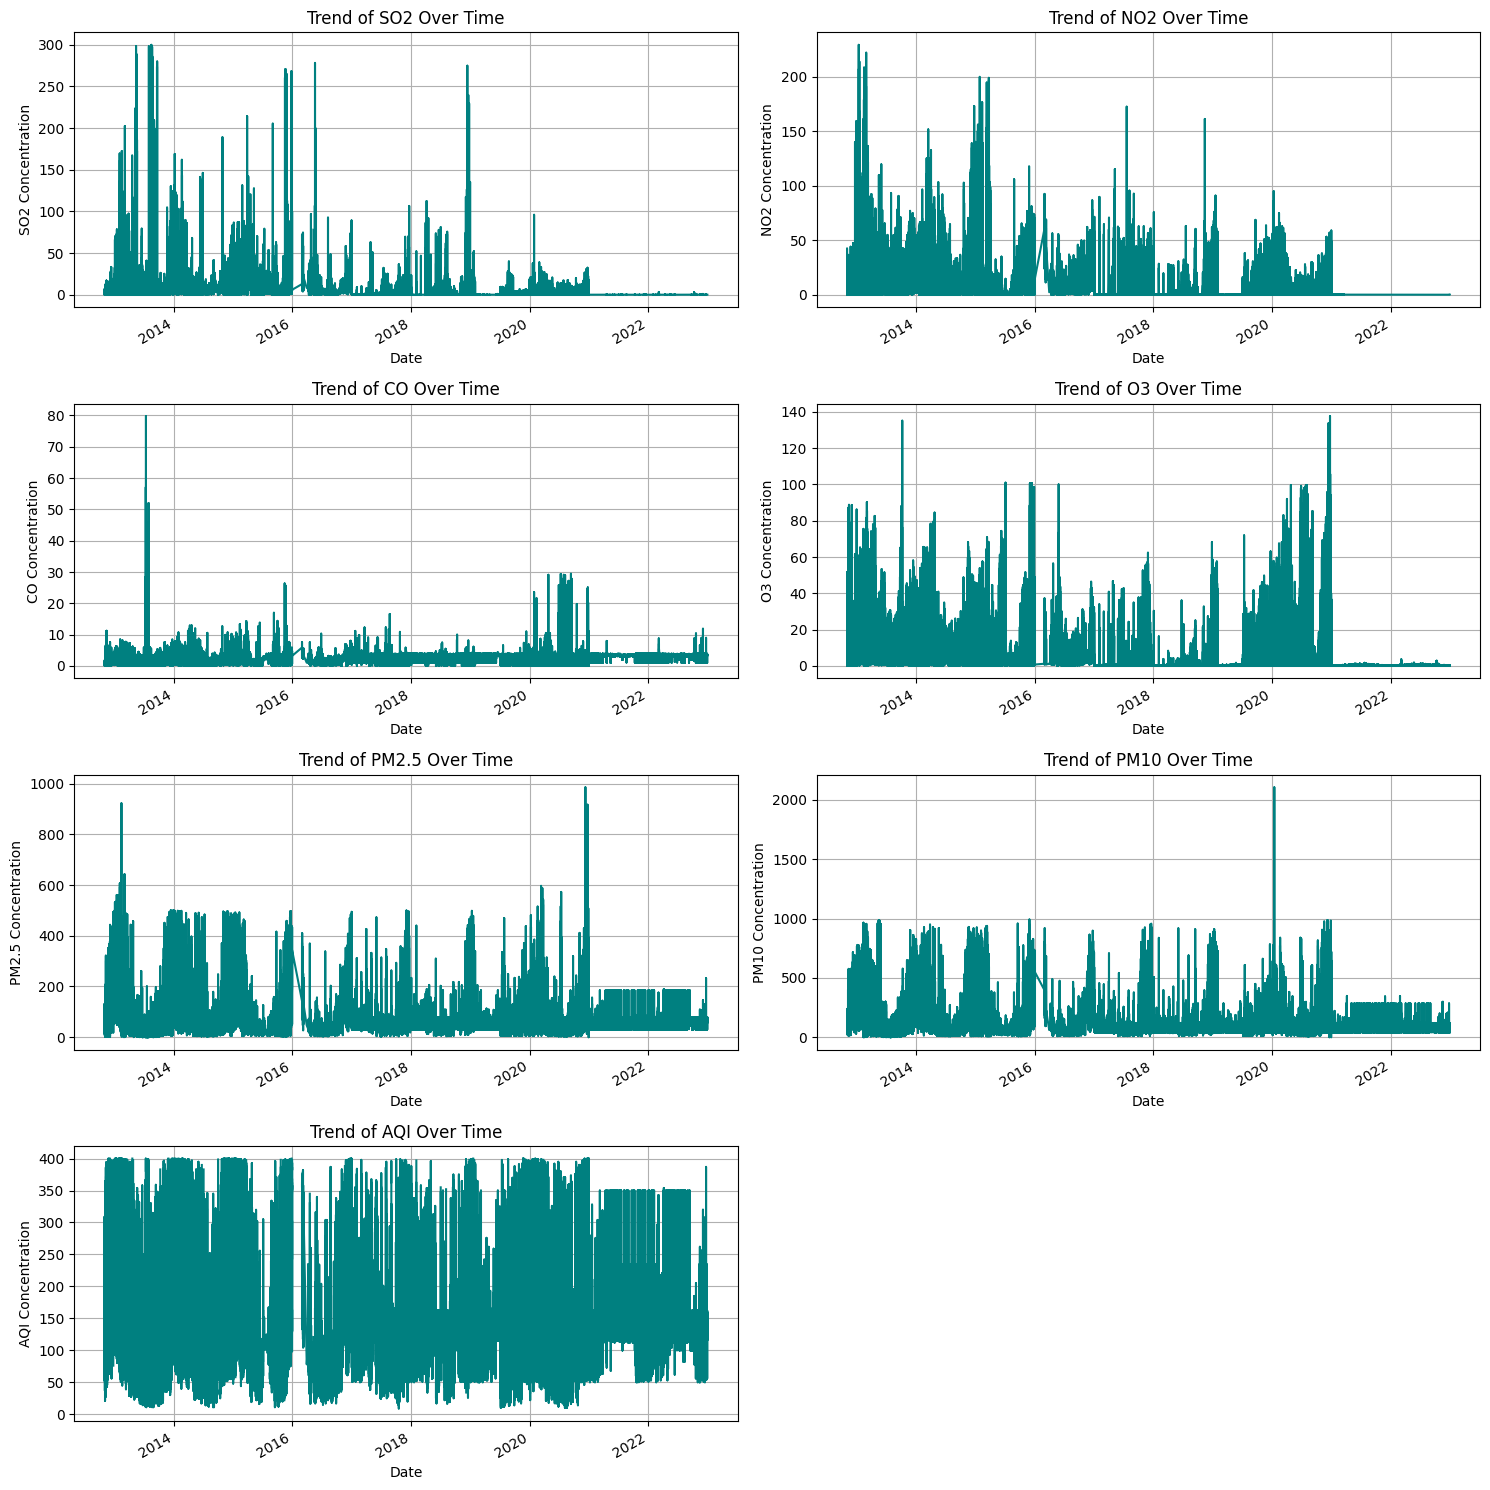

In [ ]:
# Select the numerical columns
numerical_cols = ['SO2', 'NO2', 'CO', 'O3', 'PM2.5', 'PM10', 'AQI']

# Create line plots for each numerical variable over time
plt.figure(figsize=(15, 15))

for i, col in enumerate(numerical_cols):
    plt.subplot(4, 2, i + 1) # Adjust subplot grid as needed (e.g., 4x2 for 7 plots)
    df[col].plot(kind='line', color='teal')
    plt.title(f'Trend of {col} Over Time')
    plt.xlabel('Date')
    plt.ylabel(f'{col} Concentration')
    plt.grid(True)

plt.tight_layout()
plt.show()

## Resample and analyze trends

### Subtask:
Resample the data to different frequencies (e.g., weekly, monthly, yearly) and analyze trends using rolling averages or other smoothing techniques.


Weekly Average Data:


,SO2,NO2,CO,O3,PM2.5,PM10,AQI
Date,,,,,,,
2012-11-04,2.733048,6.201810,0.598286,12.499238,54.966667,100.989429,120.590476
2012-11-11,7.059032,3.947455,1.363190,5.289104,97.948710,171.925233,192.101504
2012-11-18,7.042184,3.639367,1.852943,7.748513,88.777532,170.899082,188.851613
2012-11-25,4.746846,4.508615,1.237231,4.773692,131.949154,233.440000,239.139130
2012-12-02,5.358395,9.334568,1.493179,10.132068,134.826235,222.937407,275.129568



Yearly Average Data:


,SO2,NO2,CO,O3,PM2.5,PM10,AQI
Date,,,,,,,
2012-12-31,5.732550,8.640783,1.614479,7.131254,135.484071,219.537104,253.040423
2013-12-31,10.261862,16.646301,1.581758,10.536243,82.950290,139.866122,146.988868
2014-12-31,7.379433,14.943583,1.692384,8.335497,108.941976,175.303321,187.497038
2015-12-31,9.761807,13.710839,1.986736,6.363952,109.513223,187.571358,197.253730
2016-12-31,5.189384,13.161265,1.827529,7.107994,57.101518,105.803215,113.428839


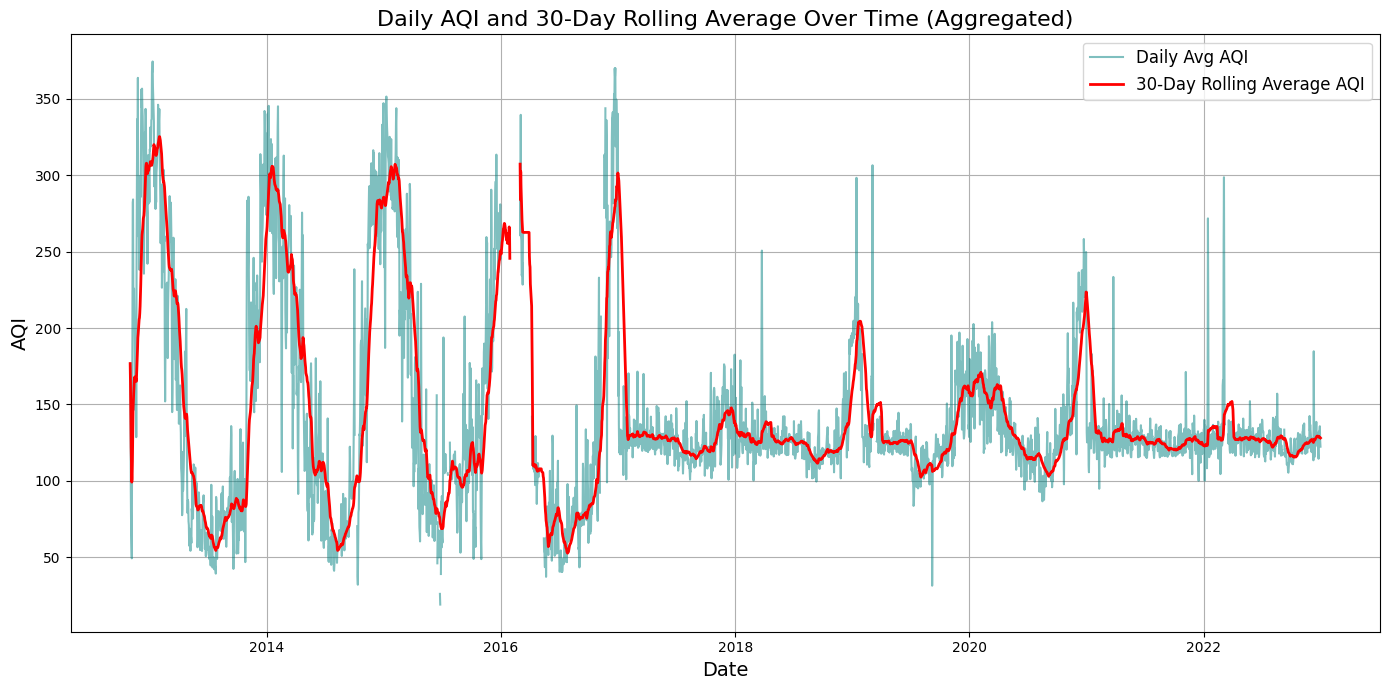

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Define the numerical columns to analyze
numerical_cols = ['SO2', 'NO2', 'CO', 'O3', 'PM2.5', 'PM10', 'AQI']

# Ensure index is sorted
df.sort_index(inplace=True)

# Resample the DataFrame to a weekly frequency ('W') and calculate the mean
weekly_avg_data = df[numerical_cols].resample('W').mean()

# Display the first few rows of the weekly_avg_data DataFrame
print("Weekly Average Data:")
display(weekly_avg_data.head())

# Resample the DataFrame to a yearly frequency ('YE') instead of 'Y' and calculate the mean
yearly_avg_data = df[numerical_cols].resample('YE').mean()

# Display the first few rows of the yearly_avg_data DataFrame
print("\nYearly Average Data:")
display(yearly_avg_data.head())

# To calculate a rolling average across the entire dataset without conflicts from duplicate times (due to multiple locations),
# we aggregate the data daily first to get a clean, monotonic timeline.
daily_df = df[numerical_cols].resample('D').mean()
daily_df.sort_index(inplace=True)

# Calculate the 30-day rolling average for the 'AQI' column on the daily aggregated data
daily_df['AQI_rolling_avg_30d'] = daily_df['AQI'].rolling(window='30D').mean()

# Create a line plot showing the daily average 'AQI' and the 'AQI_rolling_avg_30d' over time
plt.figure(figsize=(14, 7))
plt.plot(daily_df.index, daily_df['AQI'], label='Daily Avg AQI', alpha=0.5, color='teal')
plt.plot(daily_df.index, daily_df['AQI_rolling_avg_30d'], label='30-Day Rolling Average AQI', color='red', linewidth=2)
plt.title('Daily AQI and 30-Day Rolling Average Over Time (Aggregated)', fontsize=16)
plt.xlabel('Date', fontsize=14)
plt.ylabel('AQI', fontsize=14)
plt.legend(fontsize=12)
plt.grid(True)
plt.tight_layout()
plt.show()

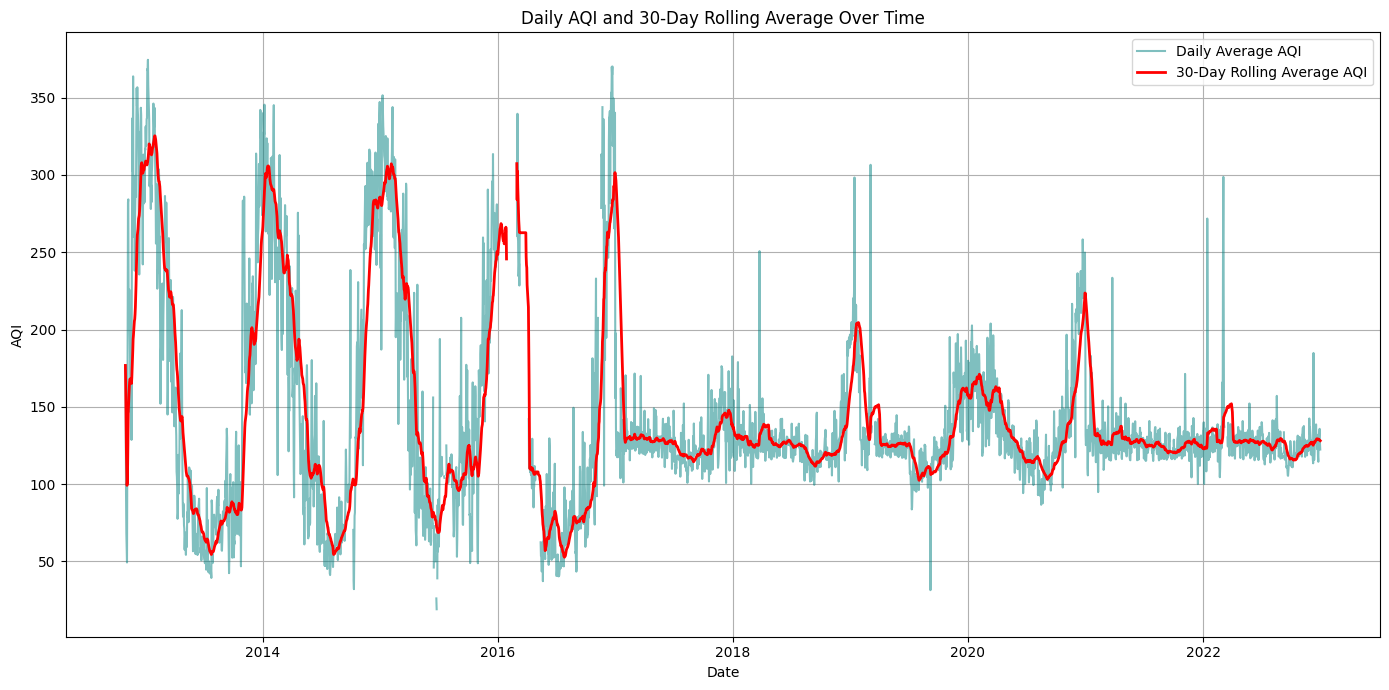

In [ ]:
# Drop rows with NaT index values to prevent the rolling window error
df_clean = df[df.index.notna()]

# Sort the index to ensure it is monotonic
df_clean = df_clean.sort_index()

# Because we have multiple locations with duplicate timestamps, we aggregate the
# data daily first to get a clean, unique timeline for the 30-day rolling average
daily_df = df_clean[['AQI']].resample('D').mean()

# Calculate the 30-day rolling average on the aggregated daily timeline
daily_df['AQI_rolling_avg_30d'] = daily_df['AQI'].rolling(window='30D').mean()

# Create a line plot showing the daily average 'AQI' and the 'AQI_rolling_avg_30d'
plt.figure(figsize=(14, 7))
plt.plot(daily_df.index, daily_df['AQI'], label='Daily Average AQI', alpha=0.5, color='teal')
plt.plot(daily_df.index, daily_df['AQI_rolling_avg_30d'], label='30-Day Rolling Average AQI', color='red', linewidth=2)
plt.title('Daily AQI and 30-Day Rolling Average Over Time')
plt.xlabel('Date')
plt.ylabel('AQI')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Analyze seasonality and trend

### Subtask:
Decompose time series of key variables to identify and separate trend, seasonality, and residual components.


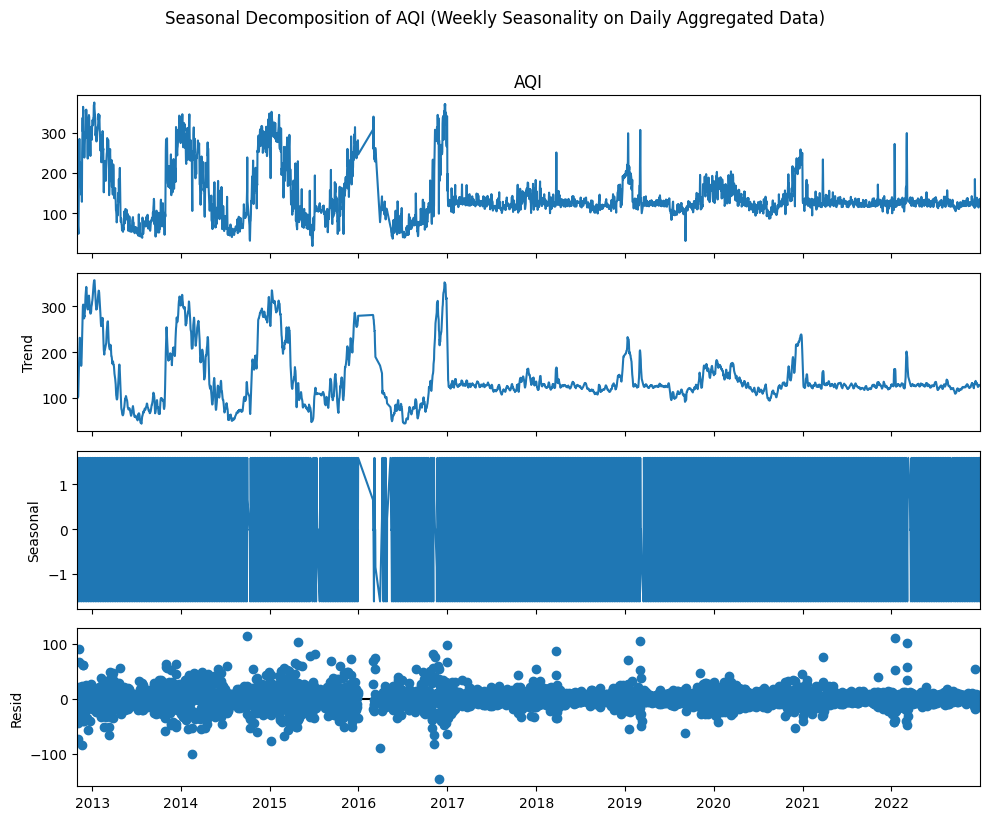

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt

# 1. Aggregate daily first to remove duplicate timestamps from multiple locations
# This creates a monotonic daily index for AQI
daily_aqi = df['AQI'].resample('D').mean()

# 2. Drop any missing values to prevent NaN propagation in the decomposition
aqi_ts = daily_aqi.dropna()

# 3. Apply seasonal_decompose with a period suitable for the frequency
# Since the aggregated data is daily, a period of 7 represents weekly seasonality,
# or 365 represents annual seasonality. Let's use a weekly period (7 days).
decomposition_aqi = seasonal_decompose(aqi_ts, model='additive', period=7)

# 4. Plot the decomposed components
fig = decomposition_aqi.plot()
fig.set_size_inches(10, 8)
fig.suptitle('Seasonal Decomposition of AQI (Weekly Seasonality on Daily Aggregated Data)', y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
# Calculate the number of missing (NaN) values in the AQI column
null_aqi_count = df['AQI'].isna().sum()
pct_null_aqi = df['AQI'].isna().mean() * 100

print(f"Total NaN values in the 'AQI' column: {null_aqi_count} ({pct_null_aqi:.2f}% of total rows)")

# Display the first few rows where AQI is NaN
print("\nFirst 5 rows with missing AQI values:")
display(df[df['AQI'].isna()].head())

Total NaN values in the 'AQI' column: 8842 (3.26% of total rows)

First 5 rows with missing AQI values:


,Time,Location,PM2.5,PM10,NO2,O3,CO,SO2,AQI,AQI_Category,Hour,Month,Year,Season
Date,,,,,,,,,,,,,,
2012-11-08,22:00:00,Darussalam,204.20,534.46,35.85,1.67,2.17,0.51,NaN,Severe,22.0,11.0,2012.0,Autumn
2012-11-08,22:00:00,Narayonganj,178.02,470.56,0.03,0.24,1.11,5.62,NaN,Severe,22.0,11.0,2012.0,Autumn
2012-11-08,NaT,Narayonganj,205.77,500.88,0.10,0.19,1.81,6.30,NaN,Severe,NaN,11.0,2012.0,Autumn
2012-11-08,23:00:00,Narayonganj,208.90,488.52,0.07,0.19,1.50,5.95,NaN,Severe,23.0,11.0,2012.0,Autumn
2012-11-09,22:00:00,Narayonganj,286.85,533.42,0.04,0.24,1.72,6.19,NaN,Severe,22.0,11.0,2012.0,Autumn


## Correlations with time components

### Subtask:
Investigate correlations between numerical variables and time components (e.g., hour of day, day of week, month, season).


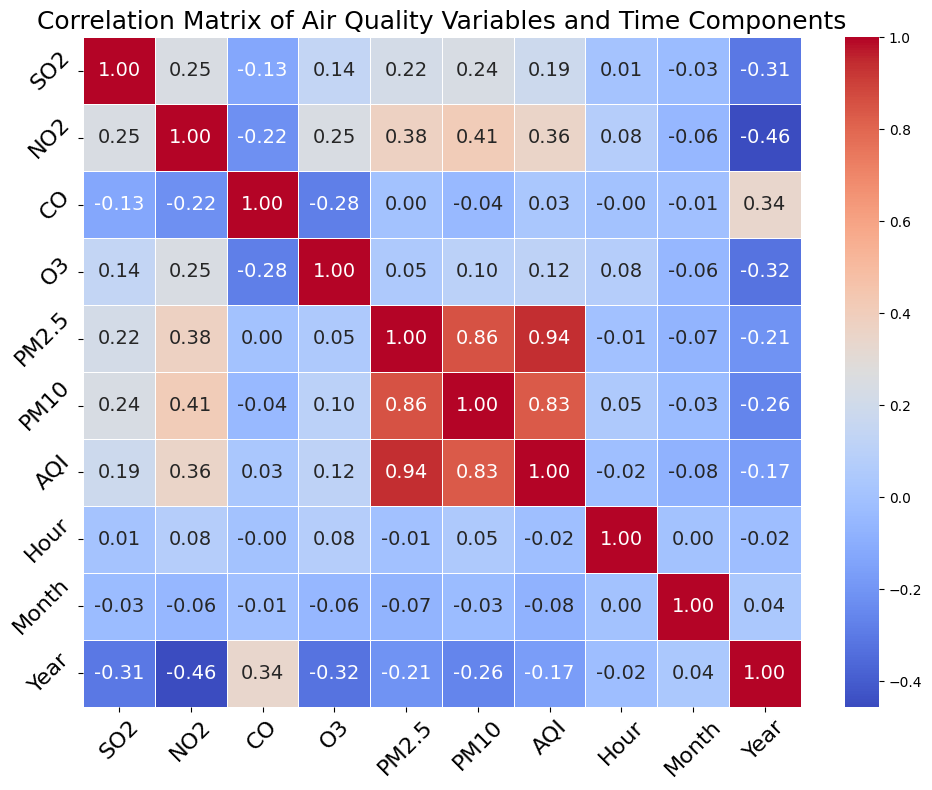

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical columns and time component columns
analysis_cols = ['SO2', 'NO2', 'CO', 'O3', 'PM2.5', 'PM10', 'AQI', 'Hour', 'Month', 'Year']
df_analysis = df[analysis_cols]

# Calculate the correlation matrix
correlation_matrix_time = df_analysis.corr()

# Plot heatmap
plt.figure(figsize=(10, 8))
ax = sns.heatmap(
    correlation_matrix_time,
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
    linewidths=0.5,
    annot_kws={"size": 14}  # value font size
)

# Title
plt.title('Correlation Matrix of Air Quality Variables and Time Components', fontsize=18)

# Axis label font size
ax.set_xlabel('', fontsize=16)
ax.set_ylabel('', fontsize=16)

# Tick label font size
ax.tick_params(axis='x', labelsize=16, rotation=45)
ax.tick_params(axis='y', labelsize=16, rotation=45)

plt.tight_layout()
plt.show()


# Task
Analyze and visualize the daily normalized trends of key pollutants across different locations using the dataset "air_quality_data.csv".

## Normalize pollutant data by location

### Subtask:
Normalize the pollutant concentration values for each location.


In [ ]:
# Define the pollutant columns
pollutant_cols = ['SO2', 'NO2', 'CO', 'O3', 'PM2.5', 'PM10']

# Create a new DataFrame by copying the original DataFrame
df_normalized = df.copy()

# Normalize pollutant concentration values for each location using min-max scaling
for col in pollutant_cols:
    if col in df_normalized.columns:
        df_normalized[col] = df_normalized.groupby('Location')[col].transform(
            lambda x: (x - x.min()) / (x.max() - x.min())
        )
    else:
        print(f"Warning: Column '{col}' not found in DataFrame.")

# Display the head of the normalized DataFrame
display(df_normalized.head())

,Time,Location,PM2.5,PM10,NO2,O3,CO,SO2,AQI,AQI_Category,Hour,Month,Year,Season
Date,,,,,,,,,,,,,,
2012-11-01,06:00:00,Narayonganj,0.105445,0.115727,0.000147,0.015317,0.120061,0.031880,245.0,Poor,6.0,11.0,2012.0,Autumn
2012-11-01,23:00:00,Narayonganj,0.123486,0.232562,0.000147,0.005361,0.212766,0.029394,302.0,Very Poor,23.0,11.0,2012.0,Autumn
2012-11-01,01:00:00,Narayonganj,0.069332,0.084661,0.000147,0.002680,0.132219,0.027017,126.0,Moderate,1.0,11.0,2012.0,Autumn
2012-11-01,21:00:00,Narayonganj,0.111425,0.223111,0.000589,0.006701,0.165653,0.027395,265.0,Poor,21.0,11.0,2012.0,Autumn
2012-11-01,22:00:00,Narayonganj,0.133639,0.241637,0.000589,0.005744,0.208207,0.030151,309.0,Very Poor,22.0,11.0,2012.0,Autumn


## Resample to daily frequency

### Subtask:
Resample the normalized data to a daily frequency and calculate the mean.


In [ ]:
# Select the pollutant columns from the df_normalized DataFrame
pollutant_cols = ['SO2', 'NO2', 'CO', 'O3', 'PM2.5', 'PM10']
df_normalized_pollutants = df_normalized[pollutant_cols]

# Resample the selected data to a daily frequency ('D') and calculate the mean for each day
daily_normalized_trends = df_normalized_pollutants.resample('D').mean()

# Display the first few rows of the new DataFrame
print("Daily averaged normalized pollutant data:")
display(daily_normalized_trends.head())

Daily averaged normalized pollutant data:


,SO2,NO2,CO,O3,PM2.5,PM10
Date,,,,,,
2012-11-01,0.021467,0.105325,0.128800,0.018515,0.096368,0.138747
2012-11-02,0.017442,0.009009,0.082254,0.103855,0.077814,0.124614
2012-11-03,0.011735,0.036079,0.053803,0.150776,0.054012,0.087416
2012-11-04,0.007101,0.059041,0.057457,0.245908,0.047076,0.059720
2012-11-05,0.109779,0.027024,0.026481,0.104408,0.050143,0.055164


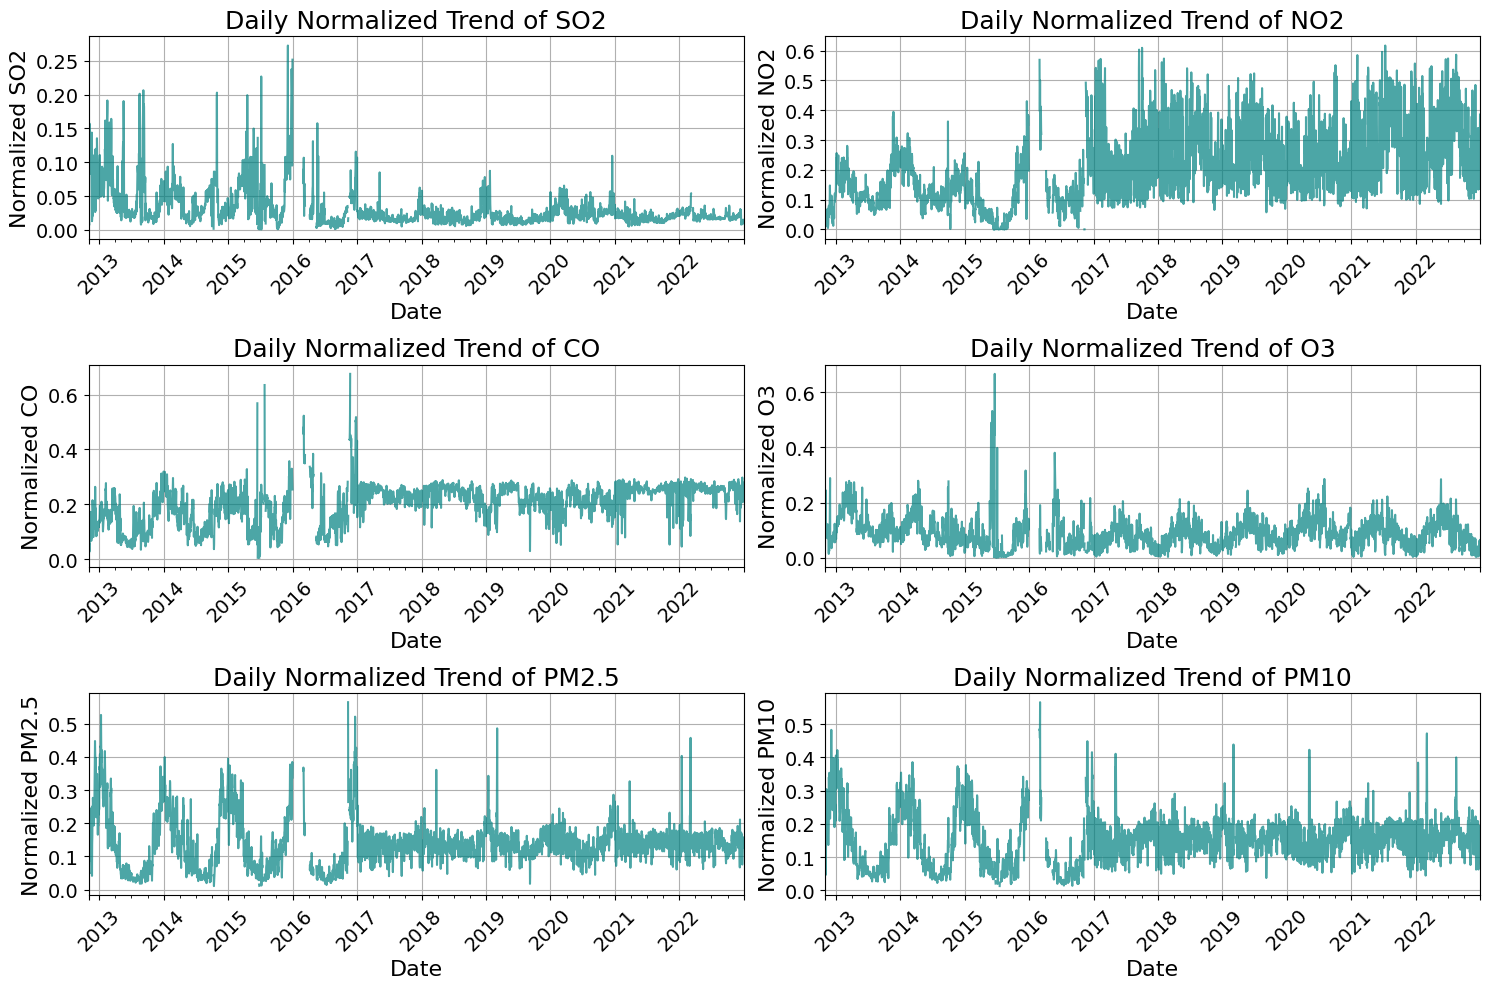

In [ ]:
# Create line plots for each normalized pollutant variable over time (daily average)
plt.figure(figsize=(15, 10))

pollutant_cols = ['SO2', 'NO2', 'CO', 'O3', 'PM2.5', 'PM10']

for i, col in enumerate(pollutant_cols):
    plt.subplot(3, 2, i + 1)
    daily_normalized_trends[col].plot(kind='line', color='teal', alpha=0.7)
    plt.title(f'Daily Normalized Trend of {col}', fontsize=18)
    plt.xlabel('Date', fontsize=16)
    plt.ylabel(f'Normalized {col}',fontsize=16)
    plt.xticks(rotation=45, fontsize=14)
    plt.yticks(fontsize=14)
    plt.grid(True)

plt.tight_layout()
plt.show()